# Đồ án 1 – Nhận dạng chữ số viết tay (MNIST)

| Mục | Nội dung | Module dùng |
|---|---|---|
| 0 | Thiết lập | – |
| 1 | Dữ liệu và EDA | `data.py` |
| 2 | Công cụ đánh giá chung | `metrics.py` |
| 3 | Multinomial Naïve Bayes | `naive_bayes.py` |
| 4 | Logistic Regression (Gradient Descent) | `logistic.py` |
| 5 | MLP (backpropagation) | `mlp.py` |
| 6 | Random Forest (n_estimators, OOB, feature importance) | `random_forest.py` |
| 7 | Tổng hợp trên validation | – |
| 8 | Đánh giá cuối trên test (**chạy đúng một lần**) | – |
| 9 | Thí nghiệm mở rộng: chữ số người Việt | `vn_digits.py`, `experiments.py` |
| 10 | Nâng cao: tăng cường dữ liệu và thí nghiệm độ bền | `experiments.py` |
| 11 | Lưu mô hình cho demo (`app.py`) | – |

**Dữ liệu:** `load_and_prepare` tự tải MNIST về `data/mnist.npz` ở lần chạy đầu tiên (cần mạng). Có thể tải trước bằng `python src/data.py` ở thư mục gốc repo.

**Cách dùng:** đặt `QUICK = True` ở mục 0 để chạy trên 5.000 ảnh train với ít epoch/ít cây (vài phút cho cả notebook). Đặt `QUICK = False`, `RUN_TEST = True`để chạy full-test.

## 0. Thiết lập

In [121]:
# Chạy MỘT LẦN khi mới tạo môi trường, xong thì Restart kernel.
# Lưu ý: tên gói là "scikit-learn" (KHÔNG phải "sklearn"); khi import thì dùng "import sklearn".
%pip install numpy scipy pandas matplotlib scikit-learn opencv-python Pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%load_ext autoreload
%autoreload 2

import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_root(start=None):
    # Tìm thư mục gốc repo: đi ngược lên từ thư mục hiện tại tới khi gặp src/data.py

    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "data.py").exists():
            return p
    raise FileNotFoundError(f"Không tìm thấy src/data.py khi đi ngược lên từ {start}. "
                            "Mở notebook từ trong thư mục repo, hoặc gán ROOT = Path(r'đường/dẫn/tới/mnist-project').")

ROOT = find_root()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

# ---- Cấu hình chung ----
QUICK = False       # True: chạy thử nhanh trên tập con; False: chạy đầy đủ để lấy số liệu báo cáo
RUN_TEST = True     # chỉ bật ở lần chạy cuối cùng (mục 8)
SEED = 42
N_TRAIN = 5000 if QUICK else None                  # None = dùng đủ 54.000 ảnh train
EPOCHS_LR = 5 if QUICK else 20
EPOCHS_MLP = 5 if QUICK else 15
N_TREES = 10 if QUICK else 50
SWEEP_SEEDS = [0] if QUICK else [0, 1, 2]          # số seed cho các thí nghiệm siêu tham số

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def save_fig(name):
    """Lưu hình hiện tại vào results/ để đưa vào báo cáo."""
    plt.savefig(RESULTS / f"{name}.png", dpi=200, bbox_inches="tight")

def fit_timed(model, *args, **kwargs):
    """Huấn luyện model.fit(*args) và đo thời gian. Trả về (model đã huấn luyện, số giây)."""
    t = time.perf_counter()
    model.fit(*args, **kwargs)
    return model, time.perf_counter() - t

# scikit-learn chỉ dùng để ĐỐI CHIẾU (mục 3.2, 4.3, 6.3); thiếu thì các ô đó tự bỏ qua
import importlib.util
HAS_SKLEARN = importlib.util.find_spec("sklearn") is not None
if not HAS_SKLEARN:
    print("CHƯA CÀI scikit-learn -> bỏ qua các ô đối chiếu sklearn. "
          "Cài bằng ô %pip ở trên (gói 'scikit-learn'), rồi Restart kernel.")

print("ROOT =", ROOT, "| QUICK =", QUICK, "| RUN_TEST =", RUN_TEST)

ROOT = D:\Nhan_dang_mau\do_an_gk | QUICK = False | RUN_TEST = True


## 1. Dữ liệu

Lần chạy đầu tiên, `load_and_prepare` tự tải MNIST về `data/mnist.npz` (cần mạng). Có thể tải trước bằng `python src/data.py` ở thư mục gốc repo.

`load_and_prepare` đi đúng pipeline của `MNISTPreprocessor` trong `src/data.py`: làm phẳng ảnh thành 784 chiều, chia 255 (min-max) và chia tập phân tầng **đúng** 54.000 / 6.000 / 10.000.

In [4]:
from data import load_and_prepare, load_mnist_raw, summary

X_tr, y_tr, X_va, y_va, X_te, y_te = load_and_prepare(val_ratio=0.1, seed=SEED, n_train=N_TRAIN)
summary(X_tr, y_tr, X_va, y_va, X_te, y_te)

train: X (54000, 784) float32 [0.0, 1.0]  mỗi lớp: [5331, 6068, 5362, 5518, 5258, 4879, 5326, 5638, 5266, 5354]
val  : X (6000, 784) float32 [0.0, 1.0]  mỗi lớp: [592, 674, 596, 613, 584, 542, 592, 627, 585, 595]
test : X (10000, 784) float32 [0.0, 1.0]  mỗi lớp: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


### 1.1 Phân tích khám phá dữ liệu (EDA)
EDA dùng ảnh gốc 0–255 của toàn bộ tập train.

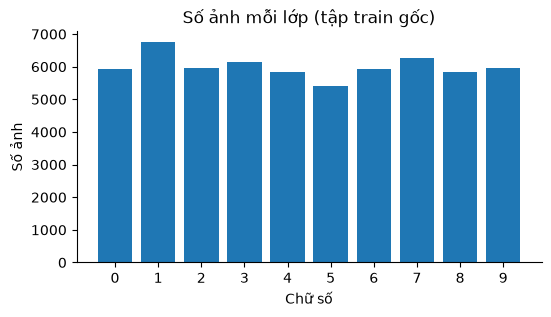

Ít nhất: 5421 | nhiều nhất: 6742


In [124]:
X_raw, y_raw, _, _ = load_mnist_raw()

# Hình 1: số ảnh mỗi lớp
counts = np.bincount(y_raw, minlength=10)
plt.figure(figsize=(6, 3))
plt.bar(range(10), counts)
plt.xticks(range(10)); plt.xlabel("Chữ số"); plt.ylabel("Số ảnh")
plt.title("Số ảnh mỗi lớp (tập train gốc)")
save_fig("eda_class_counts"); plt.show()
print("Ít nhất:", counts.min(), "| nhiều nhất:", counts.max())

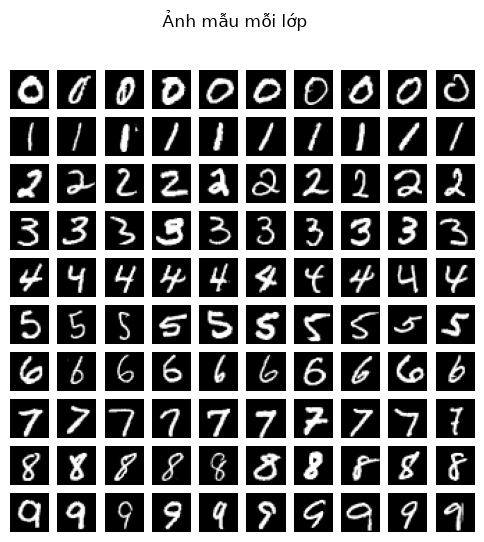

In [125]:
# Hình 2: ảnh mẫu, mỗi hàng một chữ số
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 10, figsize=(6, 6))
for k in range(10):
    idx = rng.choice(np.where(y_raw == k)[0], 10, replace=False)
    for j, i in enumerate(idx):
        axes[k, j].imshow(X_raw[i], cmap="gray"); axes[k, j].axis("off")
plt.suptitle("Ảnh mẫu mỗi lớp")
save_fig("eda_samples"); plt.show()

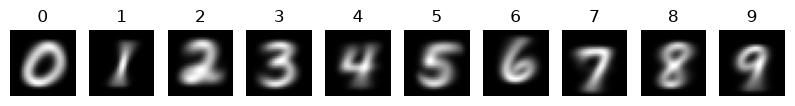

In [126]:
# Hình 3: ảnh trung bình mỗi lớp
mean_img = np.stack([X_raw[y_raw == k].mean(0) for k in range(10)])
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for k in range(10):
    axes[k].imshow(mean_img[k], cmap="gray"); axes[k].set_title(str(k)); axes[k].axis("off")
save_fig("eda_mean_images"); plt.show()

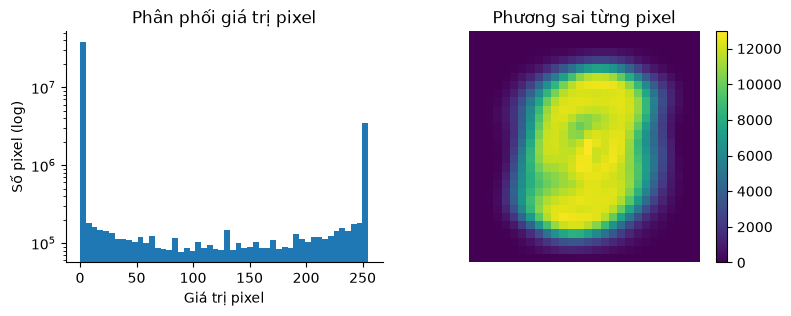

Số pixel luôn bằng 0: 67 / 784


In [127]:
# Hình 4: histogram giá trị pixel; Hình 5: bản đồ phương sai pixel
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(X_raw.ravel(), bins=50, log=True)
axes[0].set_xlabel("Giá trị pixel"); axes[0].set_ylabel("Số pixel (log)"); axes[0].set_title("Phân phối giá trị pixel")
var_map = X_raw.reshape(len(X_raw), -1).astype(np.float32).var(0).reshape(28, 28)
im = axes[1].imshow(var_map, cmap="viridis"); axes[1].axis("off"); axes[1].set_title("Phương sai từng pixel")
plt.colorbar(im, ax=axes[1])
save_fig("eda_pixels"); plt.show()
print("Số pixel luôn bằng 0:", int((var_map == 0).sum()), "/ 784")

**Nhận xét EDA**:
- Hình 1: Tập dữ liệu huấn luyện gốc có sự phân bố các lớp chữ số khá cân bằng, trong đó số lượng ảnh dao động ổn định trong khoảng từ hơn 5.000 đến gần 7.000 ảnh cho mỗi lớp từ 0 đến 9.
- Hình 3: Dựa vào đặc điểm hình thái của các ảnh trung bình, các cặp chữ số dễ bị nhầm lẫn nhất là 4 và 9 do có cấu trúc nét vòng và nét dọc tương đồng, cùng với cặp 3 và 8 do có chung các vòng cong xếp chồng lên nhau.
- Hình 4-5: Biểu đồ phân phối giá trị pixel cho thấy sự tập trung cao ở hai đầu (nền đen và nét trắng), trong khi biểu đồ phương sai từng pixel phản ánh rõ các vùng có mức độ biến động nét viết cao nhất tập trung tạo thành hình dáng bao quanh các chữ số ở trung tâm.

## 2. Công cụ đánh giá chung

Các mô hình đi qua cùng hàm `evaluate_model`: accuracy, precision, recall, F1 (macro) trên train và validation, cùng thời gian huấn luyện và dự đoán. Tập test **chỉ** được đánh giá ở mục 8.

In [5]:
from metrics import confusion_matrix, prf_macro

RESULTS_ROWS = []      # mỗi dòng: một mô hình trên một tập
FINAL_MODELS = {}      # cấu hình cuối của từng mô hình (chọn theo validation), dùng ở mục 8

def evaluate_model(name, model, fit_seconds, sets):
    """sets: dict tên_tập -> (X, y). Ghi kết quả vào RESULTS_ROWS và in ra."""
    for set_name, (X, y) in sets.items():
        t = time.perf_counter()
        pred = model.predict(X)
        pred_ms = (time.perf_counter() - t) / len(X) * 1000
        p, r, f1, acc = prf_macro(confusion_matrix(y, pred, 10))
        row = {"model": name, "set": set_name, "accuracy": acc, "precision": p, "recall": r,
               "f1": f1, "fit_s": fit_seconds, "pred_ms_per_img": pred_ms}
        RESULTS_ROWS.append(row)
        print(f"{name:20s} {set_name:5s} acc={acc:.4f}  F1={f1:.4f}  dự đoán {pred_ms:.4f} ms/ảnh")

def plot_cm(y_true, y_pred, title, fname):
    C = confusion_matrix(y_true, y_pred, 10)
    plt.figure(figsize=(4.5, 4))
    plt.imshow(C, cmap="Blues")
    for i in range(10):
        for j in range(10):
            plt.text(j, i, C[i, j], ha="center", va="center", fontsize=7,
                     color="white" if C[i, j] > C.max() / 2 else "black")
    plt.xticks(range(10)); plt.yticks(range(10))
    plt.xlabel("Dự đoán"); plt.ylabel("Nhãn thật"); plt.title(title)
    save_fig(fname); plt.show()

TRAIN_VAL = {"train": (X_tr, y_tr), "val": (X_va, y_va)}

## 3. Multinomial Naïve Bayes
### 3.1 Huấn luyện và đánh giá

In [129]:
from naive_bayes import MultinomialNB

nb, t_fit = fit_timed(MultinomialNB(alpha=1.0), X_tr, y_tr)
evaluate_model("Multinomial NB", nb, t_fit, TRAIN_VAL)

Multinomial NB       train acc=0.8239  F1=0.8225  dự đoán 0.0025 ms/ảnh
Multinomial NB       val   acc=0.8210  F1=0.8199  dự đoán 0.0021 ms/ảnh


### 3.2 Đối chiếu scikit-learn (phải khớp tuyệt đối)

In [130]:
if HAS_SKLEARN:
    from sklearn.naive_bayes import MultinomialNB as SkMNB

    # So sánh trên float64: với float32, sai số làm tròn khi cộng hàng nghìn ảnh
    # làm xác suất lệch cỡ 1e-4 dù công thức đúng.
    X64, Xva64 = X_tr.astype(np.float64), X_va.astype(np.float64)
    my = MultinomialNB(alpha=1.0).fit(X64, y_tr)
    sk = SkMNB(alpha=1.0).fit(X64, y_tr)
    print("log_theta khớp :", np.allclose(my.log_feature_prob, sk.feature_log_prob_))
    print("log_prior khớp :", np.allclose(my.log_prior, sk.class_log_prior_))
    print("xác suất khớp  :", np.allclose(my.predict_proba(Xva64), sk.predict_proba(Xva64)))
    print("dự đoán trùng  :", (my.predict(Xva64) == sk.predict(Xva64)).mean())
else:
    print("Chưa cài scikit-learn: bỏ qua đối chiếu.")

log_theta khớp : True
log_prior khớp : True
xác suất khớp  : True
dự đoán trùng  : 1.0


### 3.3 Siêu tham số: hệ số làm trơn α

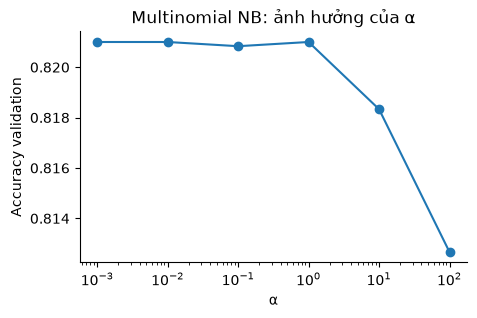

α tốt nhất trên validation: 0.001


In [131]:
alphas = [1e-3, 1e-2, 1e-1, 1, 10, 100]
val_acc = [(MultinomialNB(alpha=a).fit(X_tr, y_tr).predict(X_va) == y_va).mean() for a in alphas]
plt.figure(figsize=(5, 3))
plt.semilogx(alphas, val_acc, marker="o")
plt.xlabel("α"); plt.ylabel("Accuracy validation"); plt.title("Multinomial NB: ảnh hưởng của α")
save_fig("nb_alpha"); plt.show()
best_alpha = alphas[int(np.argmax(val_acc))]
FINAL_MODELS["Multinomial NB"] = lambda: MultinomialNB(alpha=best_alpha)
print("α tốt nhất trên validation:", best_alpha)

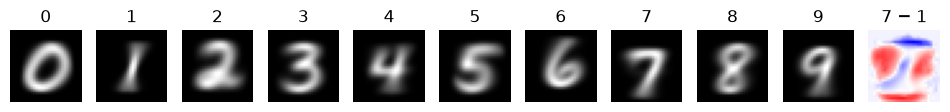

In [132]:
# Giải thích được: 10 "bản đồ mực" theta_c, và pixel nào bỏ phiếu cho 7 so với 1
fig, axes = plt.subplots(1, 11, figsize=(12, 1.5))
for k in range(10):
    axes[k].imshow(np.exp(nb.log_feature_prob[k]).reshape(28, 28), cmap="gray"); axes[k].set_title(str(k)); axes[k].axis("off")
diff = (nb.log_feature_prob[7] - nb.log_feature_prob[1]).reshape(28, 28)
lim = np.abs(diff).max()
axes[10].imshow(diff, cmap="bwr", vmin=-lim, vmax=lim); axes[10].set_title("7 − 1"); axes[10].axis("off")
save_fig("nb_theta"); plt.show()

**Nhận xét Multinomial NB**:
* Mô hình đạt độ chính xác (accuracy) và điểm F1 khá đồng đều trên cả tập huấn luyện ($\approx 82.2\%$) lẫn tập kiểm định ($\approx 82\%$), cho thấy mô hình ổn định và không bị hiện tượng quá khớp (overfitting). Tốc độ dự đoán cực kỳ nhanh (khoảng $0.0021$ ms/ảnh).
* Quá trình đối chiếu với thư viện scikit-learn cho kết quả hoàn toàn trùng khớp (True cho cả log_theta, log_prior, xác suất và tỷ lệ dự đoán trùng 1.0), chứng tỏ mã nguồn cài đặt từ đầu (from scratch) đã được hiện thực hóa chính xác.
* Giá trị tham số làm mượt $\alpha$ tốt nhất trên tập validation là $0.001$. Hình ảnh trực quan hóa các lớp chữ số từ 0 đến 9 và biểu đồ độ chênh lệch trọng số giữa lớp 7 và lớp 1 ($7 - 1$) cho thấy mô hình học được rõ rệt các vùng đặc trưng phân biệt hình thái giữa các chữ số.

## 4. Logistic Regression (Gradient Descent)
### 4.1 Gradient check

In [133]:
from logistic import LogisticRegressionGD

def softmax_np(Z):
    Z = Z - Z.max(1, keepdims=True); E = np.exp(Z); return E / E.sum(1, keepdims=True)

lr_chk = LogisticRegressionGD(lam=1e-3)
rng = np.random.default_rng(0)
lr_chk.W, lr_chk.b = rng.normal(0, 0.01, (784, 10)), np.zeros(10)
Xs, ys = X_tr[:20].astype(np.float64), y_tr[:20]
P = softmax_np(Xs @ lr_chk.W + lr_chk.b)
dW = Xs.T @ (P - np.eye(10)[ys]) / len(ys) + lr_chk.lam * lr_chk.W
rel_errs = []
for _ in range(10):
    j, k = rng.integers(784), rng.integers(10)
    old = lr_chk.W[j, k]
    lr_chk.W[j, k] = old + 1e-5; Lp = lr_chk.loss(Xs, ys)
    lr_chk.W[j, k] = old - 1e-5; Lm = lr_chk.loss(Xs, ys)
    lr_chk.W[j, k] = old
    g = (Lp - Lm) / 2e-5
    rel_errs.append(abs(g - dW[j, k]) / (abs(g) + abs(dW[j, k]) + 1e-12))
print("Sai số tương đối lớn nhất:", max(rel_errs), "→ đạt" if max(rel_errs) < 1e-6 else "→ KIỂM TRA LẠI")

Sai số tương đối lớn nhất: 4.902396681548259e-07 → đạt


### 4.2 Huấn luyện, đánh giá, learning curve

Logistic Regression  train acc=0.9244  F1=0.9234  dự đoán 0.0027 ms/ảnh
Logistic Regression  val   acc=0.9167  F1=0.9155  dự đoán 0.0024 ms/ảnh


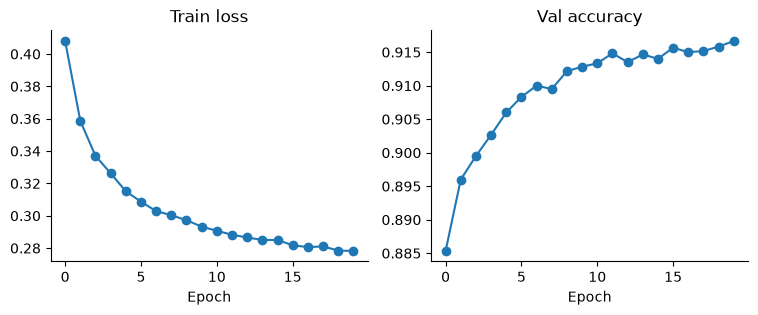

In [134]:
lr_model, t_fit = fit_timed(LogisticRegressionGD(lr=0.1, lam=1e-4, epochs=EPOCHS_LR, seed=SEED),
                            X_tr, y_tr, X_va, y_va)
evaluate_model("Logistic Regression", lr_model, t_fit, TRAIN_VAL)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(lr_model.history["train_loss"], marker="o"); axes[0].set_title("Train loss"); axes[0].set_xlabel("Epoch")
axes[1].plot(lr_model.history["val_acc"], marker="o"); axes[1].set_title("Val accuracy"); axes[1].set_xlabel("Epoch")
save_fig("lr_curve"); plt.show()

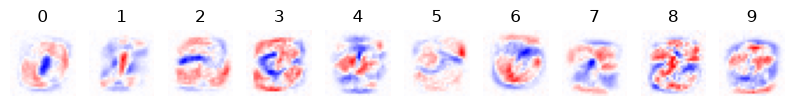

In [135]:
# Giải thích được: trọng số của mỗi lớp vẽ thành ảnh 28x28
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for k in range(10):
    w = lr_model.W[:, k].reshape(28, 28); lim = np.abs(w).max()
    axes[k].imshow(w, cmap="bwr", vmin=-lim, vmax=lim); axes[k].set_title(str(k)); axes[k].axis("off")
save_fig("lr_weights"); plt.show()

### 4.3 Đối chiếu scikit-learn
sklearn tối thiểu hoá ½‖W‖² + C·Σ loss, tương đương với công thức của ta khi C = 1/(nλ). Kỳ vọng chênh dưới khoảng 0.5%.

In [136]:
if HAS_SKLEARN:
    from sklearn.linear_model import LogisticRegression

    sk_lr = LogisticRegression(C=1 / (len(y_tr) * lr_model.lam), max_iter=300).fit(X_tr, y_tr)
    print(f"Tự cài: {(lr_model.predict(X_va) == y_va).mean():.4f} | sklearn: {sk_lr.score(X_va, y_va):.4f}")
else:
    print("Chưa cài scikit-learn: bỏ qua đối chiếu.")

Tự cài: 0.9167 | sklearn: 0.9183


### 4.4 Siêu tham số: learning rate

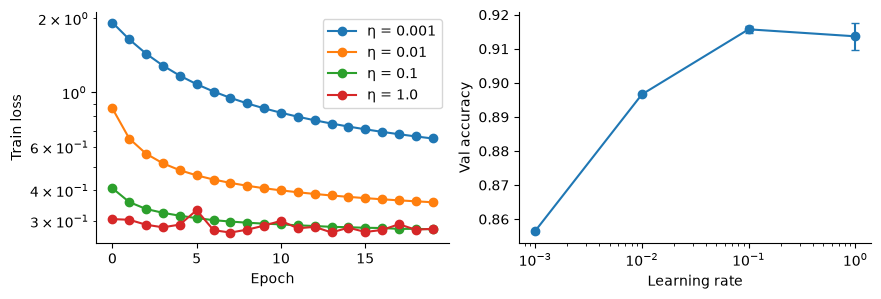

Learning rate tốt nhất: 0.1


In [137]:
rows = []
for lr in [1e-3, 1e-2, 1e-1, 1.0]:
    for s in SWEEP_SEEDS:
        m = LogisticRegressionGD(lr=lr, lam=1e-4, epochs=EPOCHS_LR, seed=s).fit(X_tr, y_tr, X_va, y_va)
        rows.append({"lr": lr, "seed": s, "val_acc": m.history["val_acc"][-1], "loss": m.history["train_loss"]})
sweep_lr = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for lr, g in sweep_lr.groupby("lr"):
    axes[0].plot(g["loss"].iloc[0], marker="o", label=f"η = {lr}")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Train loss"); axes[0].legend(); axes[0].set_yscale("log")
summ = sweep_lr.groupby("lr").val_acc.agg(["mean", "std"]).fillna(0)
axes[1].errorbar(summ.index, summ["mean"], yerr=summ["std"], marker="o", capsize=3)
axes[1].set_xscale("log"); axes[1].set_xlabel("Learning rate"); axes[1].set_ylabel("Val accuracy")
save_fig("lr_sweep"); plt.show()
sweep_lr.drop(columns="loss").to_csv(RESULTS / "lr_sweep.csv", index=False)

best_lr = summ["mean"].idxmax()
FINAL_MODELS["Logistic Regression"] = lambda: LogisticRegressionGD(lr=best_lr, lam=1e-4, epochs=EPOCHS_LR, seed=SEED)
print("Learning rate tốt nhất:", best_lr)

**Nhận xét Logistic Regression đa lớp**:
* Mô hình đạt 92.44% trên tập train và 91.67% trên tập validation. Độ chênh lệch giữa train và validation rất nhỏ (~0.77%), chứng tỏ mô hình học tốt các nét đặc trưng tổng quát chứ không bị overfitting.
* Kết quả tự cài đặt (91.67%) tiệm cận sát sao với scikit-learn (91.83%), khẳng định thuật toán đã được viết đúng.
* Sai số tương đối giữa đạo hàm đại số và đạo hàm số học cực nhỏ ($\approx 4.9 \times 10^{-7} < 10^{-5}$), xác nhận công thức tính gradient và hàm mất mát (loss function) hoàn toàn chính xác.
* Thời gian dự đoán nhanh chỉ khoảng 0.0024 ms/ảnh. Giá trị $\eta = 0.1$ giúp thuật toán Gradient Descent hội tụ ổn định và đạt hiệu năng tối ưu trên tập validation. 
* Phần trực quan trọng số thể hiện rõ các "khuôn mẫu" mà mô hình học được cho từng chữ số: vùng màu đỏ (dương) là các nét đặc trưng cần xuất hiện, trong khi vùng màu xanh (âm) là các yếu tố cần tránh giúp mô hình phân biệt chính xác chữ số đó với các số còn lại.

## 5. MLP (backpropagation)
### 5.1 Unit test với ví dụ tính tay 2–2–2

In [138]:
from mlp import MLP

t = MLP(sizes=(2, 2, 2))
t.W = [np.array([[0.5, -0.3], [0.2, 0.4]]), np.array([[0.3, -0.2], [-0.5, 0.6]])]
t.b = [np.array([0.0, 0.1]), np.zeros(2)]
p = t.forward(np.array([[1.0, 2.0]]))
gW, gb = t.backward(np.array([[1.0, 0.0]]))
assert np.allclose(p, [[0.4477, 0.5523]], atol=1e-4)
assert np.allclose(gW[0], [[-0.2762, 0.6075], [-0.5523, 1.2151]], atol=1e-4)
assert np.allclose(gW[1], [[-0.4971, 0.4971], [-0.3314, 0.3314]], atol=1e-4)
print("Unit test 2–2–2: đạt")

Unit test 2–2–2: đạt


### 5.2 Huấn luyện, đánh giá, learning curve

Epoch  1/15 | loss 0.3170 | train_acc 0.9054 | val_loss 0.1873 | val_acc 0.9452 | 0.8s
Epoch  2/15 | loss 0.1398 | train_acc 0.9586 | val_loss 0.1402 | val_acc 0.9582 | 0.8s
Epoch  3/15 | loss 0.0996 | train_acc 0.9710 | val_loss 0.1155 | val_acc 0.9667 | 1.0s
Epoch  4/15 | loss 0.0773 | train_acc 0.9771 | val_loss 0.0966 | val_acc 0.9713 | 1.1s
Epoch  5/15 | loss 0.0629 | train_acc 0.9811 | val_loss 0.0967 | val_acc 0.9703 | 1.1s
Epoch  6/15 | loss 0.0518 | train_acc 0.9851 | val_loss 0.0900 | val_acc 0.9740 | 1.1s
Epoch  7/15 | loss 0.0441 | train_acc 0.9868 | val_loss 0.0957 | val_acc 0.9712 | 1.1s
Epoch  8/15 | loss 0.0375 | train_acc 0.9895 | val_loss 0.0860 | val_acc 0.9748 | 1.2s
Epoch  9/15 | loss 0.0318 | train_acc 0.9912 | val_loss 0.0883 | val_acc 0.9753 | 1.1s
Epoch 10/15 | loss 0.0266 | train_acc 0.9931 | val_loss 0.0885 | val_acc 0.9743 | 1.1s
Epoch 11/15 | loss 0.0223 | train_acc 0.9945 | val_loss 0.0887 | val_acc 0.9747 | 1.1s
Epoch 12/15 | loss 0.0197 | train_acc 0.995

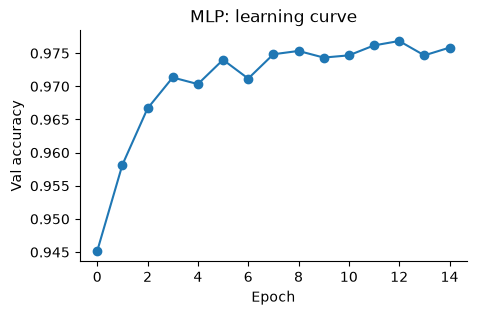

In [139]:
mlp, t_fit = fit_timed(MLP(sizes=(784, 128, 10), lr=0.05, epochs=EPOCHS_MLP, seed=SEED), X_tr, y_tr, X_va, y_va)
evaluate_model("MLP 784-128-10", mlp, t_fit, TRAIN_VAL)
plt.figure(figsize=(5, 3))
plt.plot(mlp.history["val_acc"], marker="o"); plt.xlabel("Epoch"); plt.ylabel("Val accuracy")
plt.title("MLP: learning curve"); save_fig("mlp_curve"); plt.show()

### 5.3 Siêu tham số: kiến trúc

Epoch  1/15 | loss 0.3621 | train_acc 0.8918 | val_loss 0.2355 | val_acc 0.9327 | 0.4s
Epoch  2/15 | loss 0.1860 | train_acc 0.9437 | val_loss 0.1786 | val_acc 0.9475 | 0.4s
Epoch  3/15 | loss 0.1438 | train_acc 0.9567 | val_loss 0.1520 | val_acc 0.9550 | 0.5s
Epoch  4/15 | loss 0.1202 | train_acc 0.9635 | val_loss 0.1517 | val_acc 0.9573 | 0.5s
Epoch  5/15 | loss 0.1048 | train_acc 0.9680 | val_loss 0.1335 | val_acc 0.9607 | 0.6s
Epoch  6/15 | loss 0.0950 | train_acc 0.9706 | val_loss 0.1276 | val_acc 0.9625 | 0.6s
Epoch  7/15 | loss 0.0865 | train_acc 0.9728 | val_loss 0.1260 | val_acc 0.9658 | 0.6s
Epoch  8/15 | loss 0.0802 | train_acc 0.9753 | val_loss 0.1293 | val_acc 0.9618 | 0.6s
Epoch  9/15 | loss 0.0743 | train_acc 0.9769 | val_loss 0.1272 | val_acc 0.9632 | 0.6s
Epoch 10/15 | loss 0.0679 | train_acc 0.9788 | val_loss 0.1304 | val_acc 0.9647 | 0.6s
Dừng sớm: val_acc không tăng sau 3 epoch.
Khôi phục trọng số epoch 7 (val_acc = 0.9658)
Epoch  1/15 | loss 0.3784 | train_acc 0.88

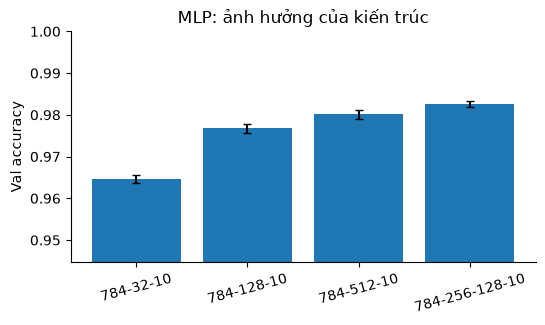

Kiến trúc tốt nhất: (784, 256, 128, 10)


In [140]:
archs = [(784, 32, 10), (784, 128, 10), (784, 512, 10), (784, 256, 128, 10)]
rows = []
for sizes in archs:
    for s in SWEEP_SEEDS:
        m = MLP(sizes=sizes, lr=0.05, epochs=EPOCHS_MLP, seed=s).fit(X_tr, y_tr, X_va, y_va)
        rows.append({"arch": "-".join(map(str, sizes)), "seed": s, "val_acc": max(m.history["val_acc"])})
sweep_mlp = pd.DataFrame(rows)
summ = sweep_mlp.groupby("arch", sort=False).val_acc.agg(["mean", "std"]).fillna(0)
plt.figure(figsize=(6, 3))
plt.bar(summ.index, summ["mean"], yerr=summ["std"], capsize=3)
plt.ylim(summ["mean"].min() - 0.02, 1); plt.ylabel("Val accuracy"); plt.xticks(rotation=15)
plt.title("MLP: ảnh hưởng của kiến trúc"); save_fig("mlp_arch"); plt.show()
sweep_mlp.to_csv(RESULTS / "mlp_arch.csv", index=False)

best_sizes = tuple(int(v) for v in summ["mean"].idxmax().split("-"))
FINAL_MODELS["MLP"] = lambda: MLP(sizes=best_sizes, lr=0.05, epochs=EPOCHS_MLP, seed=SEED)
print("Kiến trúc tốt nhất:", best_sizes)

### 5.4 Đối chiếu PyTorch (cùng kiến trúc, cùng optimizer)

In [141]:
try:
    import torch, torch.nn as nn
    torch.manual_seed(SEED)
    net = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    for layer in net:
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu"); nn.init.zeros_(layer.bias)
    opt = torch.optim.SGD(net.parameters(), lr=0.05, momentum=0.9)
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr)
    for epoch in range(EPOCHS_MLP):
        perm = torch.randperm(len(Xt))
        for s in range(0, len(Xt), 128):
            bi = perm[s:s + 128]
            opt.zero_grad(); nn.functional.cross_entropy(net(Xt[bi]), yt[bi]).backward(); opt.step()
    with torch.no_grad():
        acc_torch = (net(torch.tensor(X_va)).argmax(1).numpy() == y_va).mean()
    print(f"NumPy: {(mlp.predict(X_va) == y_va).mean():.4f} | PyTorch: {acc_torch:.4f}")
except ImportError:
    print("Chưa cài PyTorch: bỏ qua phần đối chiếu.")

NumPy: 0.9768 | PyTorch: 0.9775


**Nhận xét MLP**:
* Mô hình đạt độ chính xác trên tập train lên tới $99.73\%$ và tập validation đạt $97.68\%$. tự cài đặt bằng NumPy đạt kết quả tương đương gần như tuyệt đối với thư viện chuyên dụng PyTorch ($0.9768$ so với $0.9775$).
* Kiến trúc mạng tốt nhất tìm được là $(784, 256, 128, 10)$, vượt qua bài kiểm tra đơn vị (unit test) tính tay mạng $2-2-2$ thành công.
* Biểu đồ Learning Curve thể hiện độ chính xác validation tăng trưởng ổn định từ khoảng $94.5\%$ ở epoch đầu tiên và duy trì đỉnh ở mức khoảng $97.7\%$ từ các epoch sau. 
* Tốc độ dự đoán cực kỳ nhanh, chỉ khoảng $0.0016 - 0.0018$ ms/ảnh. 

## 6. Random Forest

### 6.1 Đo thời gian một cây trước khi chạy nhiều cây
Cây tìm ngưỡng chính xác và dự đoán bằng vòng lặp Python từng ảnh, nên đo trước cả thời gian **huấn luyện** lẫn **dự đoán**.

In [142]:
from random_forest import RandomForest

RF_PARAMS = dict(max_depth=15, min_samples_leaf=1, max_features="sqrt", voting="soft")

one, t_one = fit_timed(RandomForest(n_estimators=1, random_state=SEED, **RF_PARAMS), X_tr, y_tr)
t = time.perf_counter(); one.predict(X_va); t_pred_one = time.perf_counter() - t
print(f"Một cây: huấn luyện {t_one:.1f} s, dự đoán {len(X_va)} ảnh {t_pred_one:.1f} s")
print(f"-> {N_TREES} cây ước tính: huấn luyện {t_one * N_TREES / 60:.1f} phút, "
      f"dự đoán validation {t_pred_one * N_TREES / 60:.1f} phút")

Một cây: huấn luyện 8.9 s, dự đoán 6000 ảnh 0.0 s
-> 50 cây ước tính: huấn luyện 7.4 phút, dự đoán validation 0.0 phút


### 6.2 Huấn luyện và đánh giá (kèm OOB score)
OOB score: mỗi ảnh được dự đoán bởi các cây **không** thấy nó lúc huấn luyện (khoảng 37% số cây), nên là một ước lượng accuracy “miễn phí”, nên gần với accuracy validation.

In [143]:
rf, t_fit = fit_timed(RandomForest(n_estimators=N_TREES, oob_score=True, random_state=SEED, **RF_PARAMS), X_tr, y_tr)
evaluate_model("Random Forest", rf, t_fit, TRAIN_VAL)
print(f"OOB score: {rf.oob_score_:.4f}  |  val accuracy: {(rf.predict(X_va) == y_va).mean():.4f}")

Random Forest        train acc=0.9971  F1=0.9971  dự đoán 0.1917 ms/ảnh
Random Forest        val   acc=0.9622  F1=0.9618  dự đoán 0.1998 ms/ảnh
OOB score: 0.9549  |  val accuracy: 0.9622


### 6.3 Đối chiếu scikit-learn

In [144]:
if HAS_SKLEARN:
    from sklearn.ensemble import RandomForestClassifier

    sk_rf = RandomForestClassifier(n_estimators=N_TREES, max_depth=RF_PARAMS["max_depth"],
                                   min_samples_leaf=RF_PARAMS["min_samples_leaf"], max_features="sqrt",
                                   random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
    print(f"Tự cài: {(rf.predict(X_va) == y_va).mean():.4f} | sklearn: {sk_rf.score(X_va, y_va):.4f}")
else:
    print("Chưa cài scikit-learn: bỏ qua đối chiếu.")

Tự cài: 0.9622 | sklearn: 0.9608


### 6.4 Siêu tham số: số cây

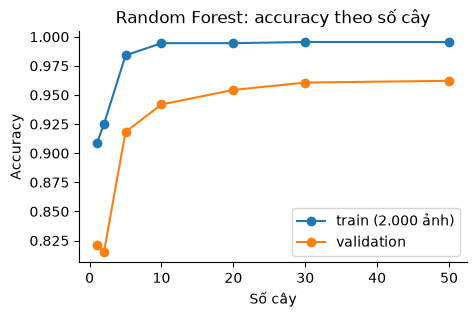

In [145]:
X_tr_sub, y_tr_sub = X_tr[:2000], y_tr[:2000]
ks = sorted(set([1, 2, 5, 10, 20, 30, 50, N_TREES]) & set(range(1, N_TREES + 1)))
acc_val, acc_tr = [], []
P_va, P_tr = 0, 0
for k, tree in enumerate(rf.trees_, start=1):
    P_va = P_va + tree.predict_proba(X_va)
    P_tr = P_tr + tree.predict_proba(X_tr_sub)
    if k in ks:
        acc_val.append((rf.classes_[P_va.argmax(1)] == y_va).mean())
        acc_tr.append((rf.classes_[P_tr.argmax(1)] == y_tr_sub).mean())
plt.figure(figsize=(5, 3))
plt.plot(ks, acc_tr, marker="o", label="train (2.000 ảnh)"); plt.plot(ks, acc_val, marker="o", label="validation")
plt.xlabel("Số cây"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Random Forest: accuracy theo số cây")
save_fig("rf_trees"); plt.show()
FINAL_MODELS["Random Forest"] = lambda: RandomForest(n_estimators=N_TREES, random_state=SEED, **RF_PARAMS)

### 6.5 Giải thích được: feature importance
Độ quan trọng của pixel = tổng (số mẫu tại nút × mức giảm Gini) ở các lần tách dùng pixel đó, trung bình qua các cây. Vẽ thành ảnh 28×28: vùng tâm sáng (quan trọng), viền tối (không bao giờ được dùng).

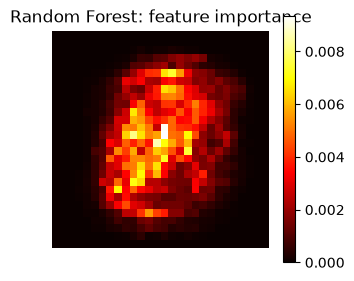

Số pixel không bao giờ được dùng để tách: 158 / 784


In [146]:
plt.figure(figsize=(3.5, 3.2))
plt.imshow(rf.feature_importances_.reshape(28, 28), cmap="hot")
plt.colorbar(); plt.axis("off"); plt.title("Random Forest: feature importance")
save_fig("rf_importance"); plt.show()
print("Số pixel không bao giờ được dùng để tách:", int((rf.feature_importances_ == 0).sum()), "/ 784")

**Nhận xét Random Forest**:
* Độ chính xác bắt đầu đi vào vùng bão hòa từ khoảng 20 đến 30 cây (đạt mức ~96% trên tập validation) và hầu như không tăng thêm khi tăng lên 50 cây.
* Điểm OOB (Out-Of-Bag) score đạt 0.9549 xấp xỉ và phản ánh rất sát với Validation accuracy (0.9622), cho thấy OOB score là một chỉ số ước lượng độ tổng quát hóa đáng tin cậy mà không cần dựa hoàn toàn vào tập validation.
* Độ chính xác trên tập train đạt 99.71%, cao hơn tập validation (96.22%) khoảng 3.5%. Mặc dù có hiện tượng overfit nhẹ (do bản chất các cây quyết định trong rừng thường được phát triển sâu), mô hình vẫn duy trì khả năng tổng quát hóa rất tốt trên tập dữ liệu mới.
* Feature Importance: : Các pixel quan trọng nhất (vùng màu sáng/vàng) tập trung chủ yếu ở vùng trung tâm ảnh—nơi chứa các nét viết chính của chữ số. Ngược lại, có 158/784 pixel (nằm ở rìa ngoài cùng màu đen) không bao giờ được sử dụng để tách nút do chỉ chứa nền trống.

## 7. Tổng hợp trên train và validation

In [147]:
table = pd.DataFrame(RESULTS_ROWS).drop_duplicates(["model", "set"], keep="last")
table.to_csv(RESULTS / "summary_train_val.csv", index=False)
table.pivot(index="model", columns="set", values=["accuracy", "f1"]).round(4)

accuracy              f1        
set                    train     val   train     val
model                                               
Logistic Regression   0.9244  0.9167  0.9234  0.9155
MLP 784-128-10        0.9973  0.9768  0.9973  0.9766
Multinomial NB        0.8239  0.8210  0.8225  0.8199
Random Forest         0.9971  0.9622  0.9971  0.9618

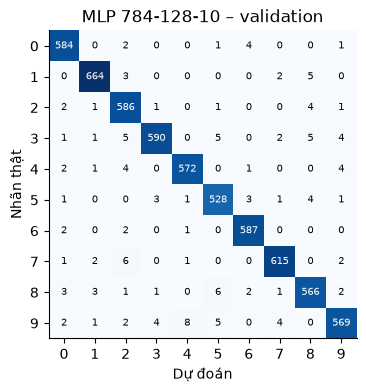

In [148]:
# Confusion matrix trên validation của mô hình tốt nhất
best_name = table[table.set == "val"].sort_values("accuracy").model.iloc[-1]
best_model = {"Multinomial NB": nb, "Logistic Regression": lr_model, "MLP 784-128-10": mlp, "Random Forest": rf}[best_name]
plot_cm(y_va, best_model.predict(X_va), f"{best_name} – validation", "cm_val_best")

## 8. Đánh giá cuối trên test

**Chỉ chạy một lần**, sau khi đã chốt mọi siêu tham số ở mục 3–6. Đặt `RUN_TEST = True` ở mục 0 rồi *Restart & Run All*. Mỗi mô hình được huấn luyện lại với cấu hình cuối trong `FINAL_MODELS`.

Multinomial NB (final) train acc=0.8248  F1=0.8235  dự đoán 0.0023 ms/ảnh
Multinomial NB (final) val   acc=0.8210  F1=0.8199  dự đoán 0.0020 ms/ảnh
Multinomial NB (final) test  acc=0.8364  F1=0.8349  dự đoán 0.0074 ms/ảnh


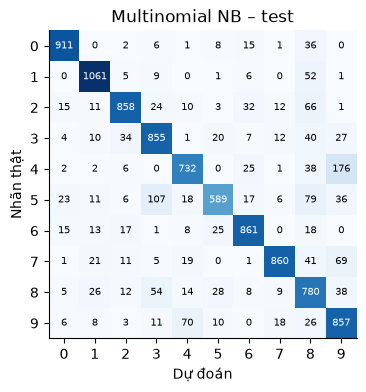

Logistic Regression (final) train acc=0.9244  F1=0.9234  dự đoán 0.0025 ms/ảnh
Logistic Regression (final) val   acc=0.9167  F1=0.9155  dự đoán 0.0020 ms/ảnh
Logistic Regression (final) test  acc=0.9213  F1=0.9201  dự đoán 0.0023 ms/ảnh


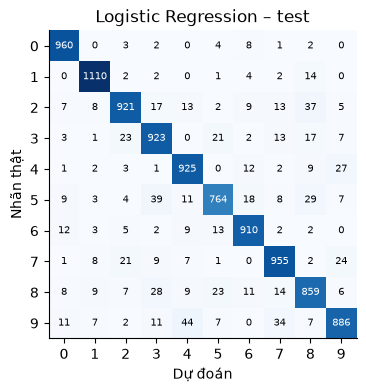

Epoch  1/15 | loss 0.2824 | train_acc 0.9146 | val_loss 0.1423 | val_acc 0.9588 | 1.8s
Epoch  2/15 | loss 0.1017 | train_acc 0.9691 | val_loss 0.1046 | val_acc 0.9710 | 1.9s
Epoch  3/15 | loss 0.0728 | train_acc 0.9768 | val_loss 0.1036 | val_acc 0.9692 | 2.4s
Epoch  4/15 | loss 0.0509 | train_acc 0.9839 | val_loss 0.0791 | val_acc 0.9770 | 2.5s
Epoch  5/15 | loss 0.0363 | train_acc 0.9886 | val_loss 0.0797 | val_acc 0.9763 | 2.5s
Epoch  6/15 | loss 0.0284 | train_acc 0.9911 | val_loss 0.0887 | val_acc 0.9768 | 2.6s
Epoch  7/15 | loss 0.0221 | train_acc 0.9933 | val_loss 0.0810 | val_acc 0.9772 | 2.6s
Epoch  8/15 | loss 0.0161 | train_acc 0.9947 | val_loss 0.0870 | val_acc 0.9798 | 2.7s
Epoch  9/15 | loss 0.0089 | train_acc 0.9978 | val_loss 0.0923 | val_acc 0.9773 | 2.7s
Epoch 10/15 | loss 0.0058 | train_acc 0.9988 | val_loss 0.0912 | val_acc 0.9788 | 2.7s
Epoch 11/15 | loss 0.0040 | train_acc 0.9993 | val_loss 0.0844 | val_acc 0.9813 | 2.7s
Epoch 12/15 | loss 0.0022 | train_acc 0.999

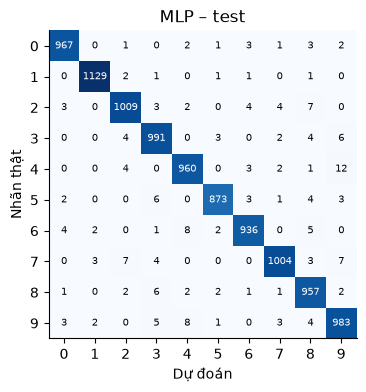

Random Forest (final) train acc=0.9971  F1=0.9971  dự đoán 0.2059 ms/ảnh
Random Forest (final) val   acc=0.9622  F1=0.9618  dự đoán 0.2079 ms/ảnh
Random Forest (final) test  acc=0.9645  F1=0.9642  dự đoán 0.2061 ms/ảnh


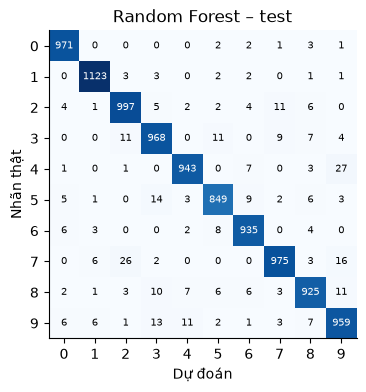

set,test,train,val
model,,,
Logistic Regression (final),0.9213,0.9244,0.9167
MLP (final),0.9809,0.9998,0.9813
Multinomial NB (final),0.8364,0.8248,0.8210
Random Forest (final),0.9645,0.9971,0.9622


In [149]:
if RUN_TEST:
    final = {}
    for name, make in FINAL_MODELS.items():
        model = make()
        args = (X_tr, y_tr, X_va, y_va) if name in ("Logistic Regression", "MLP") else (X_tr, y_tr)
        model, t_fit = fit_timed(model, *args)
        evaluate_model(name + " (final)", model, t_fit, {"train": (X_tr, y_tr), "val": (X_va, y_va), "test": (X_te, y_te)})
        final[name] = model
        plot_cm(y_te, model.predict(X_te), f"{name} – test", f"cm_test_{name.replace(' ', '_')}")
    final_table = pd.DataFrame(RESULTS_ROWS)
    final_table = final_table[final_table.model.str.endswith("(final)")]
    final_table.to_csv(RESULTS / "summary_final.csv", index=False)
    display(final_table.pivot(index="model", columns="set", values="accuracy").round(4))
else:
    print("RUN_TEST = False: bỏ qua đánh giá trên test.")

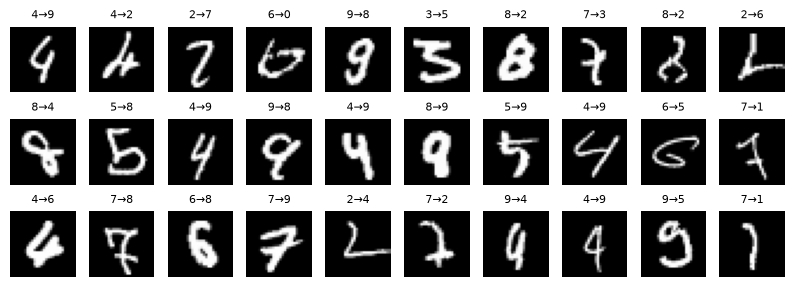

In [150]:
# Phân tích lỗi: ảnh test bị đoán sai của mô hình tốt nhất
if RUN_TEST:
    m = final[max(final, key=lambda n: (final[n].predict(X_va) == y_va).mean())]
    pred = m.predict(X_te)
    wrong = np.where(pred != y_te)[0][:30]
    fig, axes = plt.subplots(3, 10, figsize=(10, 3.4))
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(X_te[i].reshape(28, 28), cmap="gray"); ax.set_title(f"{y_te[i]}→{pred[i]}", fontsize=8); ax.axis("off")
    save_fig("errors_test"); plt.show()

## 9. Thí nghiệm mở rộng: chữ số viết tay người Việt

Cần có `data/vn_digits.npz` (tạo bằng `vn_digits.build_dataset("data/vn_raw", "data/vn_digits.npz")`). Siêu tham số giữ nguyên như `FINAL_MODELS`, **không** chỉnh lại theo tập Việt.

### 9.0 Tạo tập Việt từ ảnh phiếu

Phiếu tìm thấy: ['W01.jpg', 'W02.jpg', 'W03.jpg', 'W04.jpg', 'W05.jpg', 'W06.jpg', 'W07.jpg', 'W08.jpg', 'W09.jpg', 'W10.jpg', 'W11.jpg', 'W12.jpg', 'W13.jpg', 'W14.jpg', 'W15.jpg', 'W16.jpg', 'W17.jpg', 'W18.jpg', 'W19.jpg', 'W20.jpg', 'W21.jpg', 'W22.jpg', 'W23.jpg', 'W24.jpg', 'W25.jpg', 'W26.jpg', 'W27.jpg', 'W28.jpg', 'W29.jpg', 'W30.jpg']


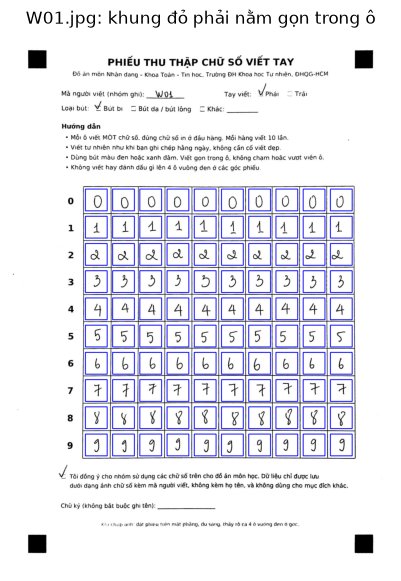

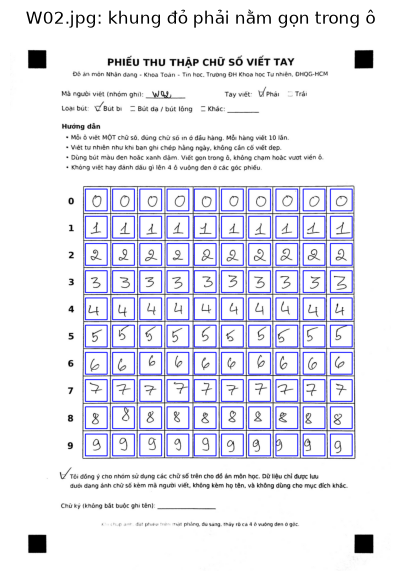

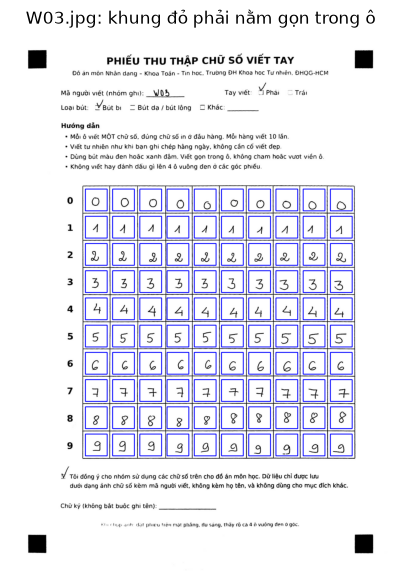

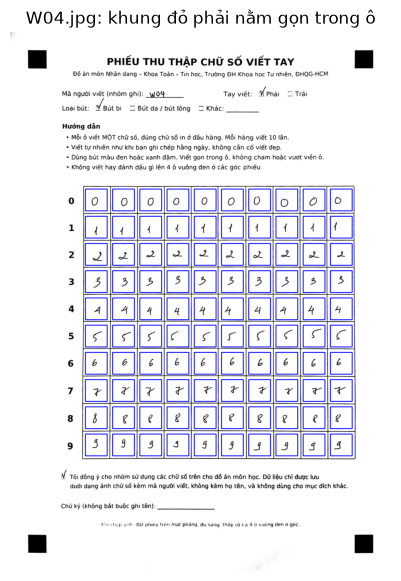

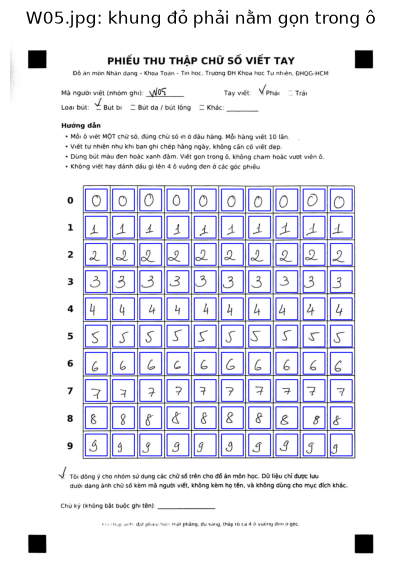

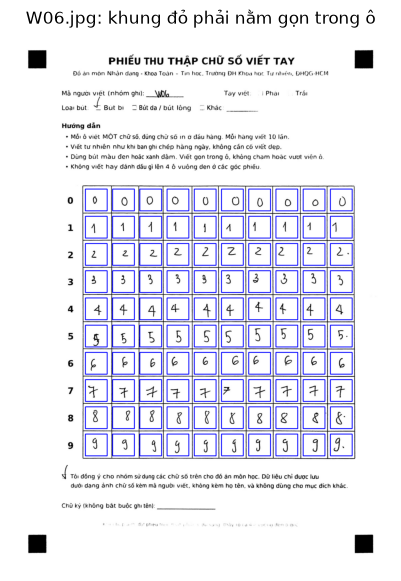

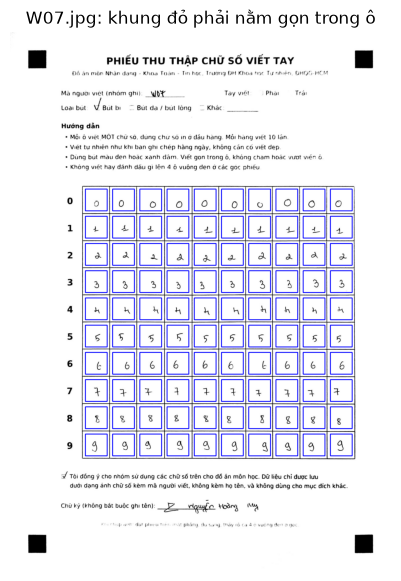

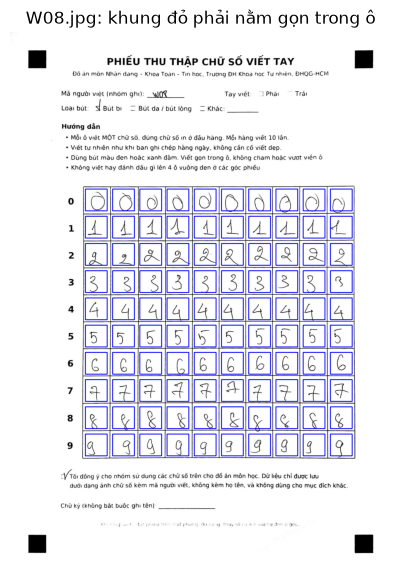

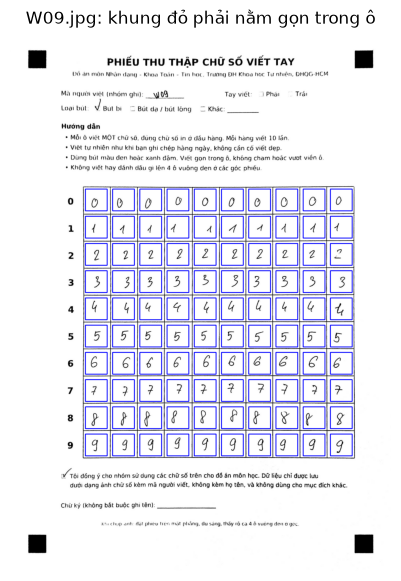

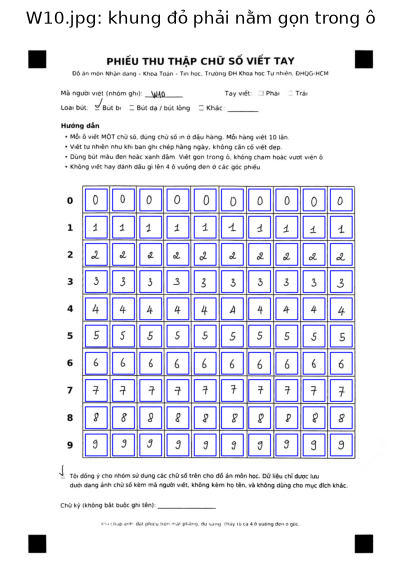

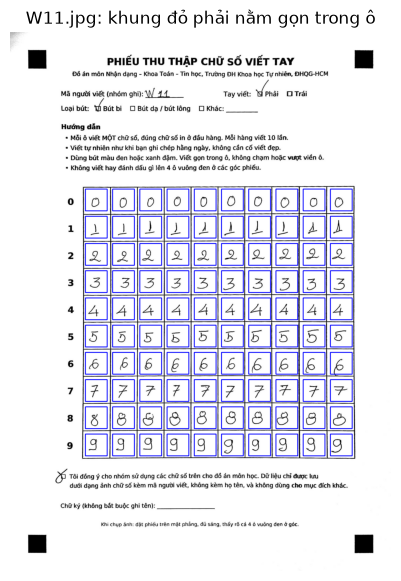

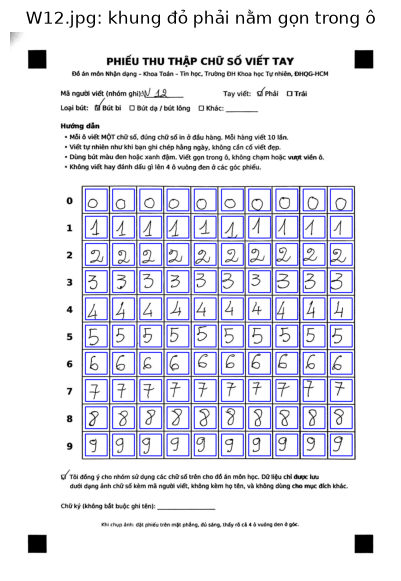

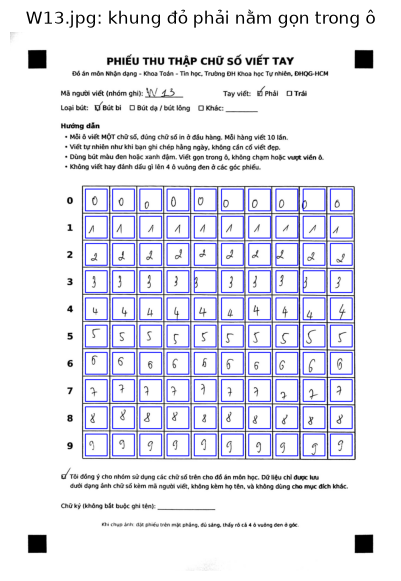

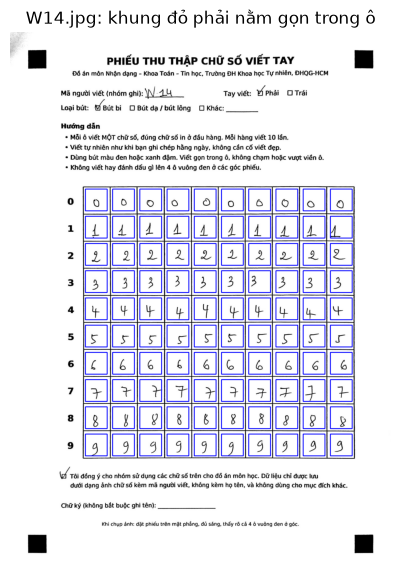

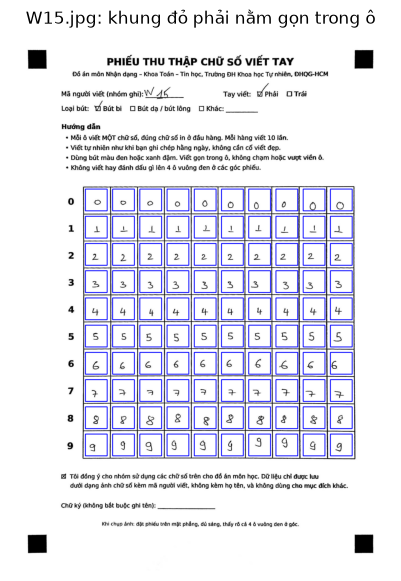

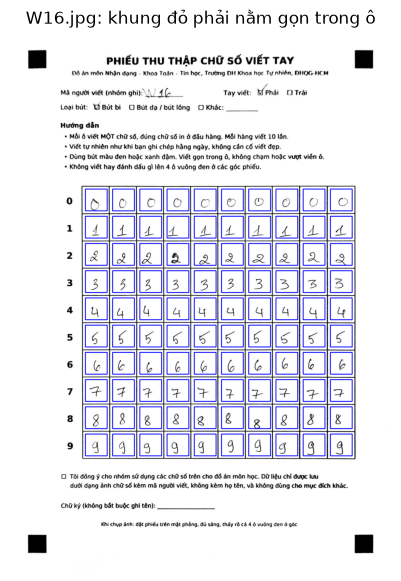

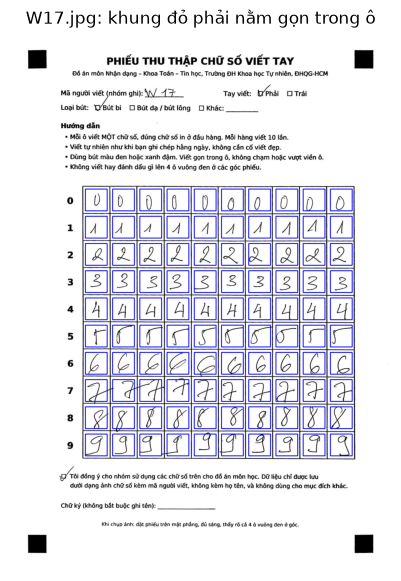

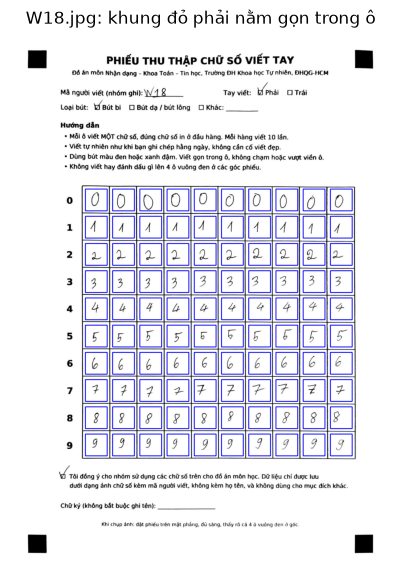

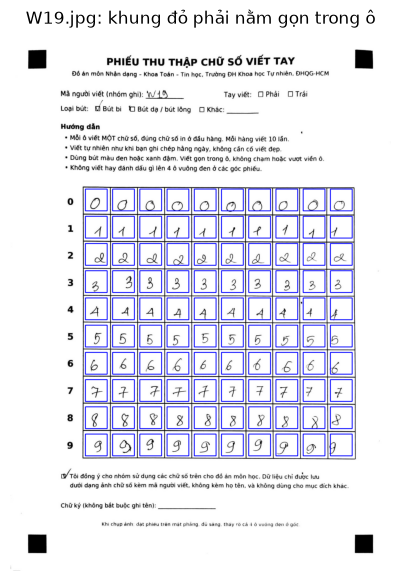

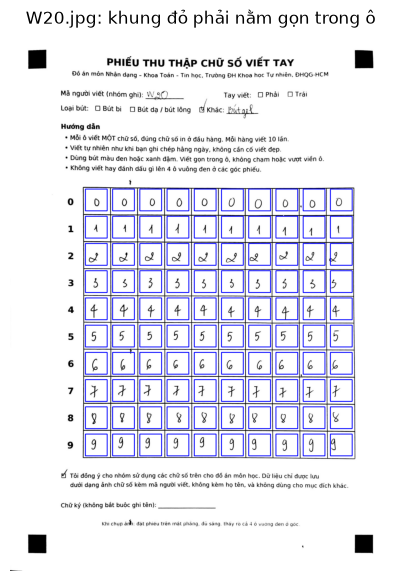

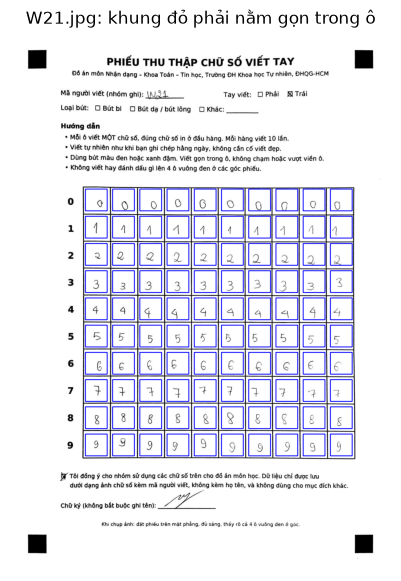

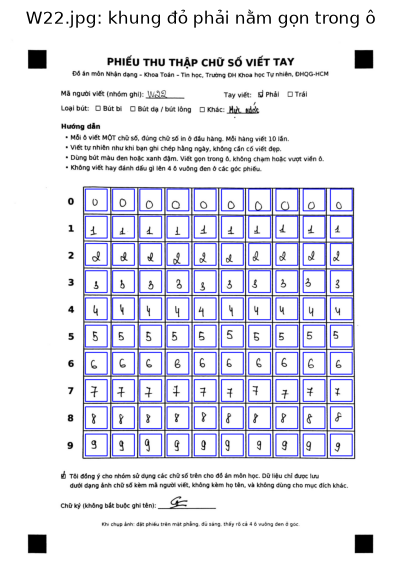

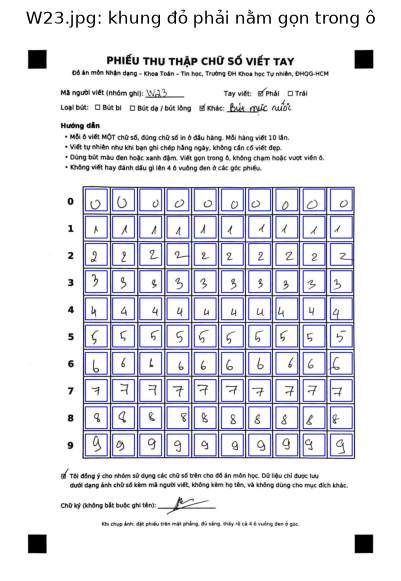

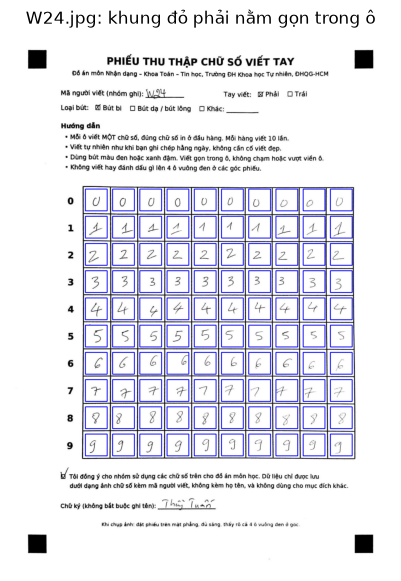

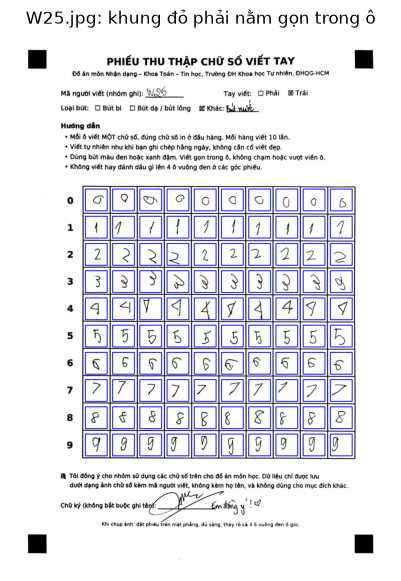

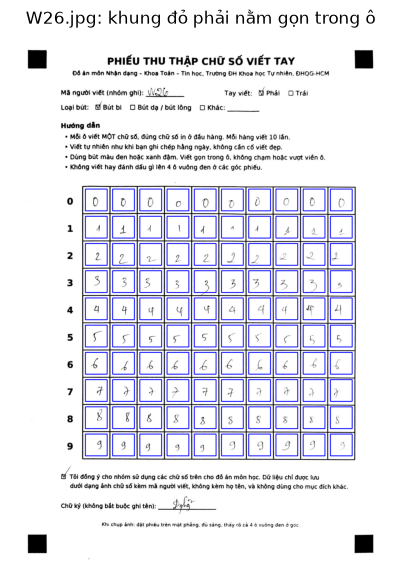

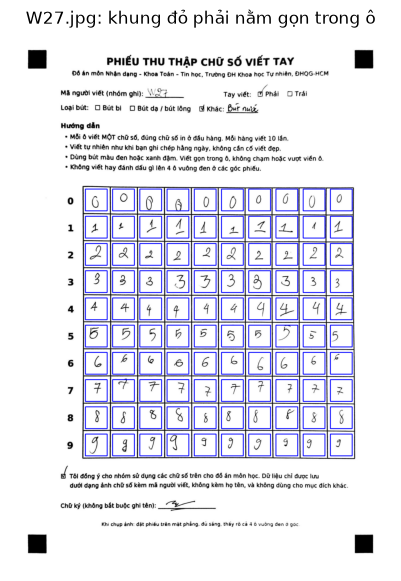

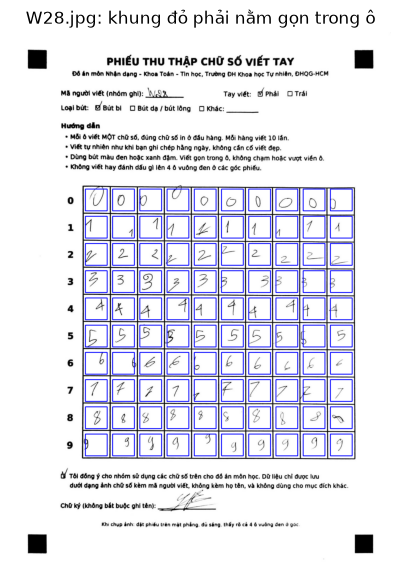

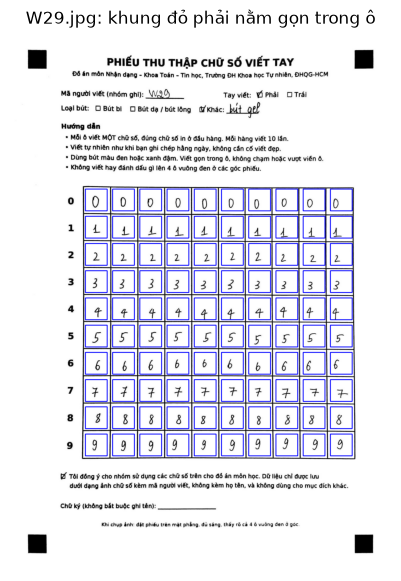

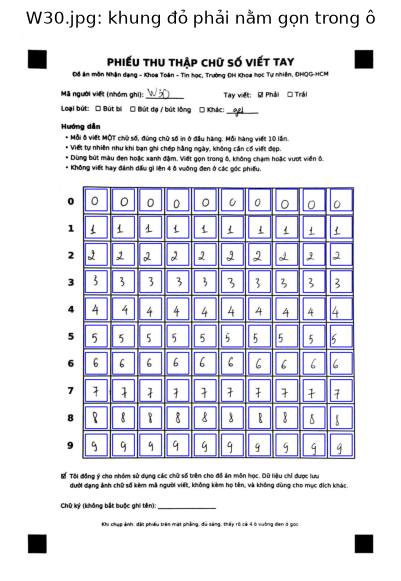

In [151]:
from vn_digits import review_sheet, process_sheet, build_dataset

RAW_DIR = ROOT / "data" / "vn_raw"
SHEETS = sorted(p for p in RAW_DIR.glob("*") if p.is_file()) if RAW_DIR.exists() else []
print("Phiếu tìm thấy:", [p.name for p in SHEETS])

# Ô 1: kiểm tra căn chỉnh từng phiếu
for path in SHEETS:
    out = RESULTS / f"review_{path.stem}.png"
    try:
        review_sheet(str(path), str(out))
    except ValueError as e:                     # ví dụ: không tìm thấy đủ 4 ô đen ở góc
        print(f"[LỖI] {path.name}: {e}")
        continue
    plt.figure(figsize=(5, 7))
    plt.imshow(plt.imread(out)[..., ::-1])      # OpenCV lưu BGR -> đảo sang RGB để hiển thị
    plt.axis("off"); plt.title(f"{path.name}: khung đỏ phải nằm gọn trong ô"); plt.show()

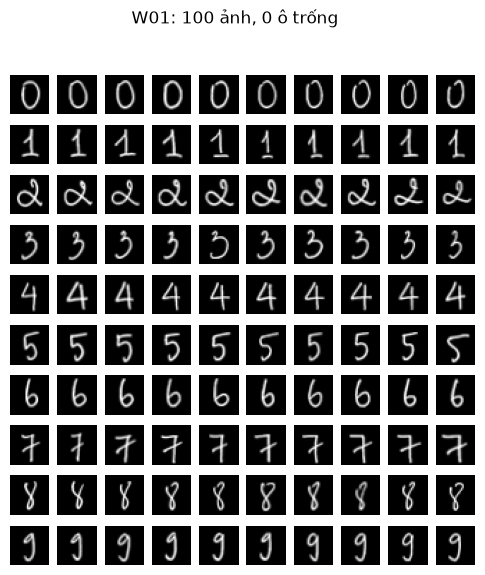

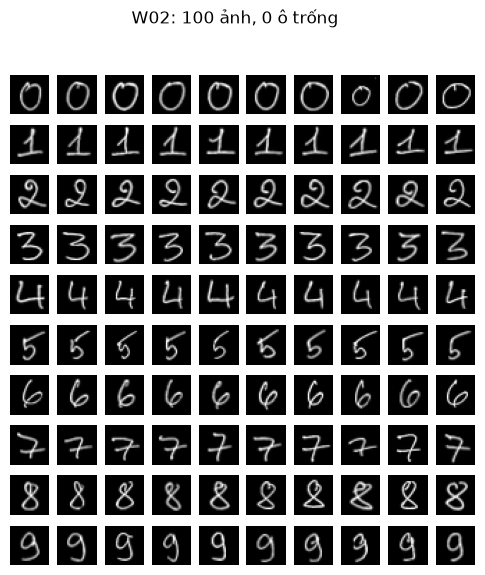

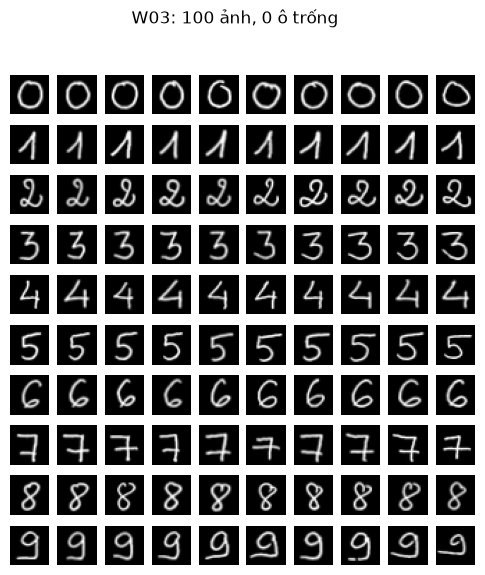

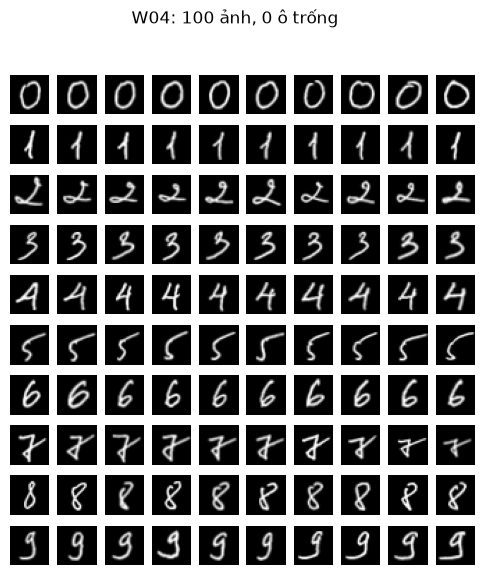

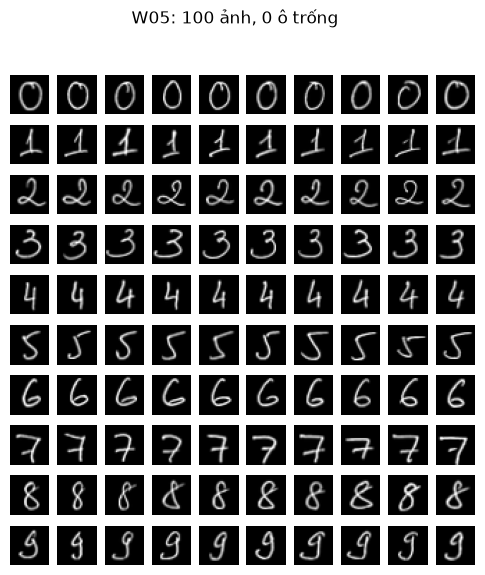

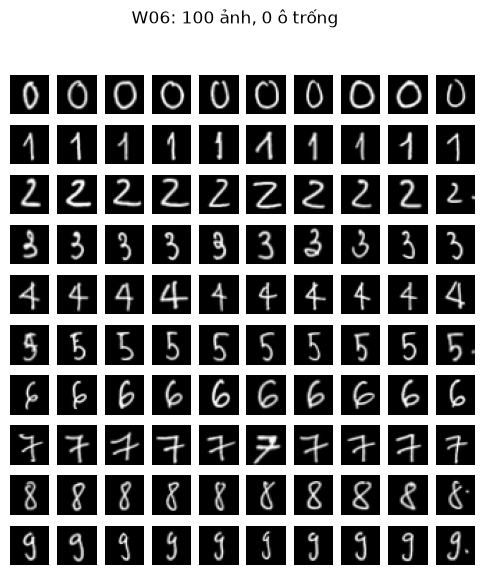

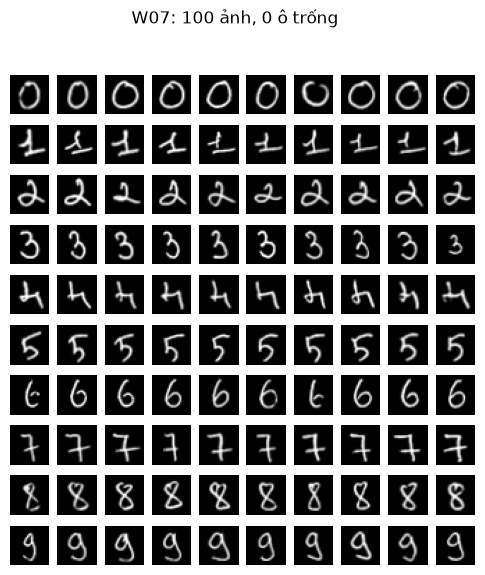

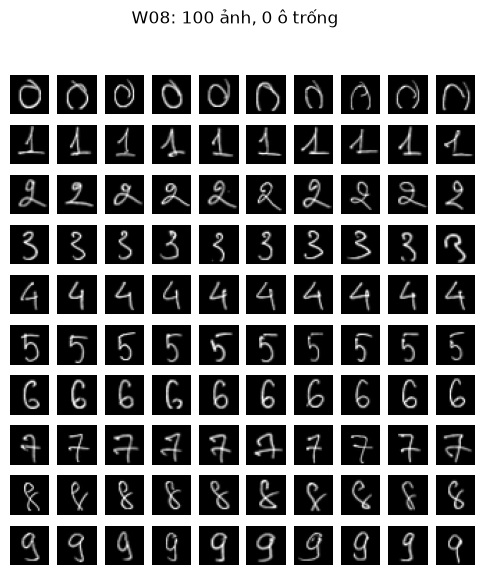

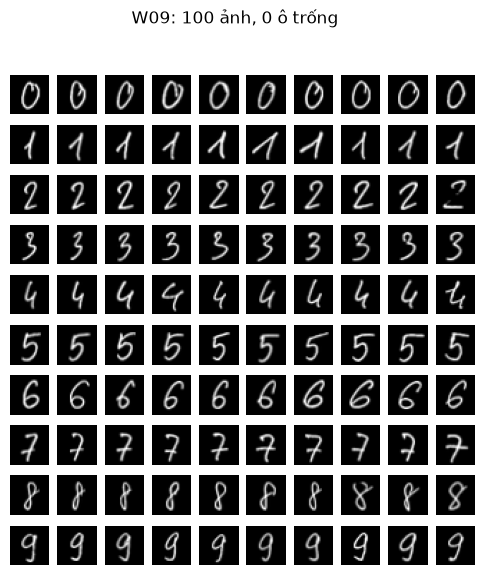

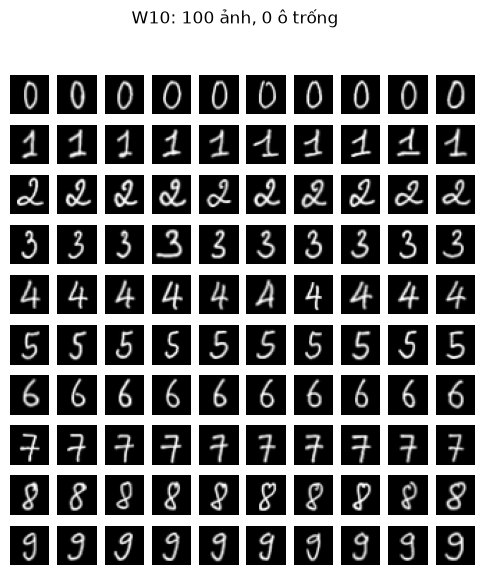

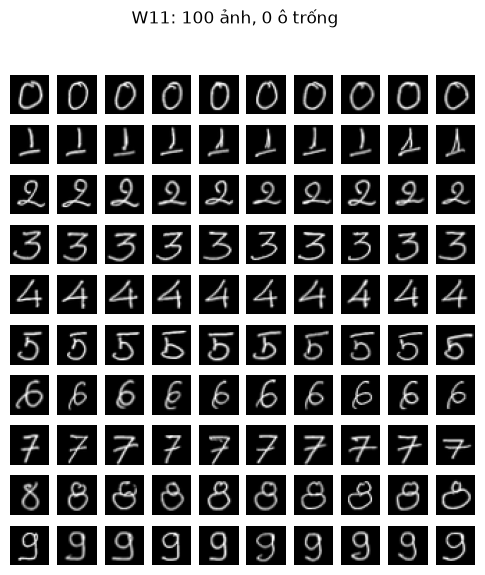

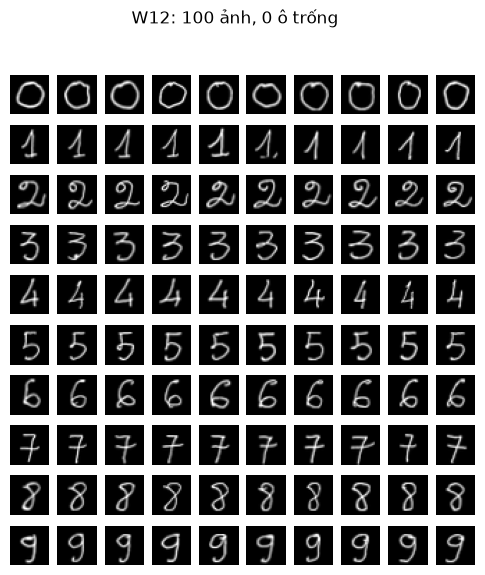

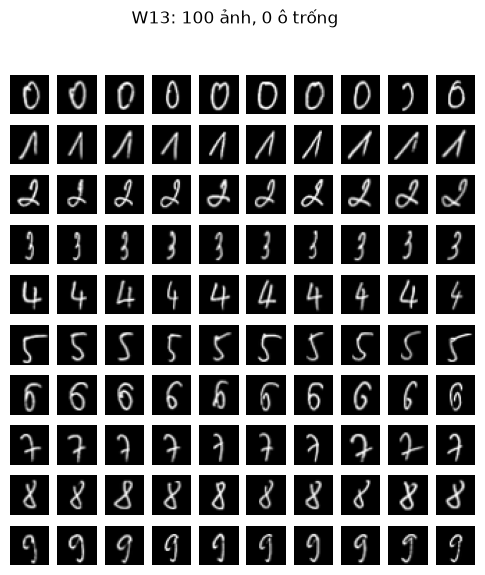

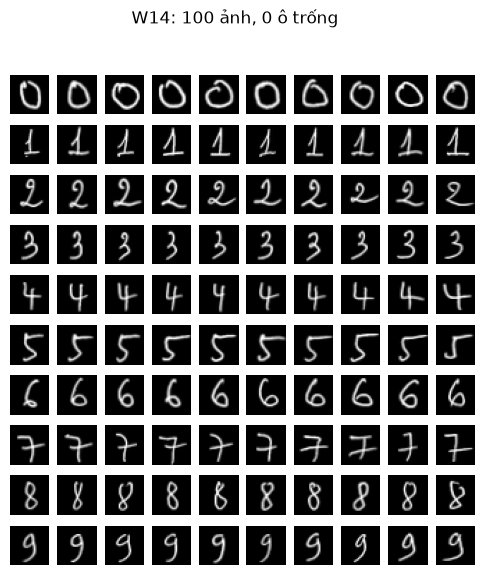

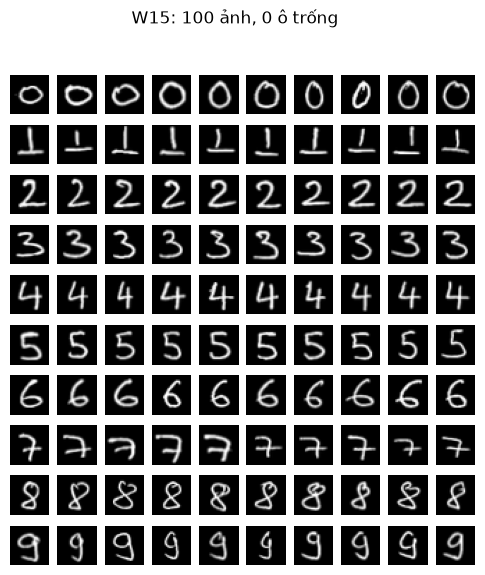

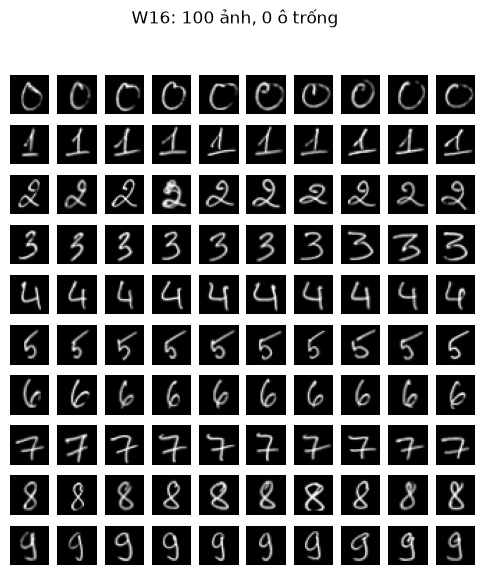

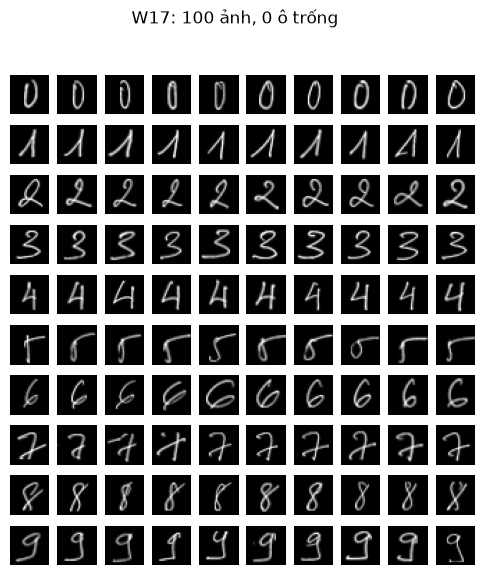

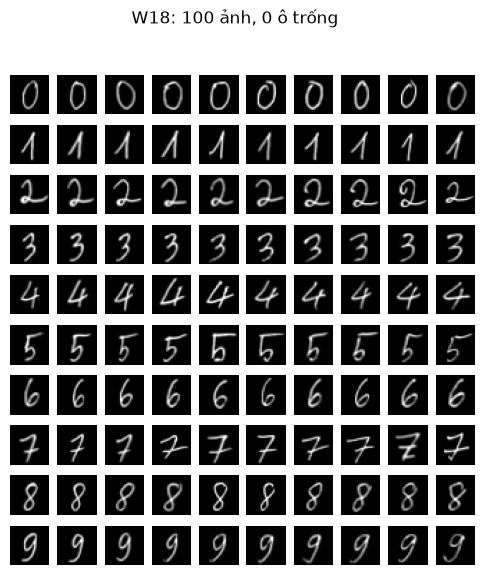

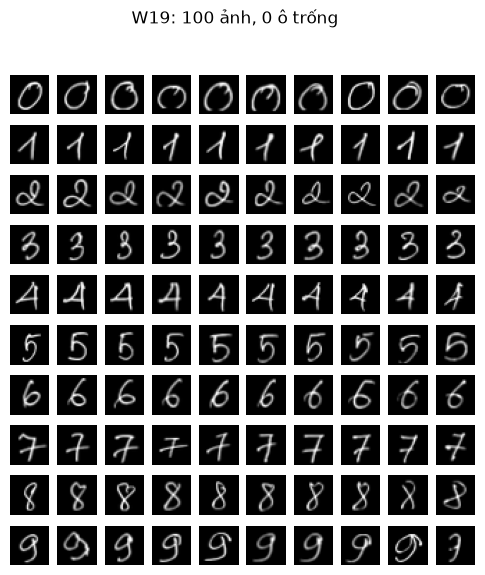

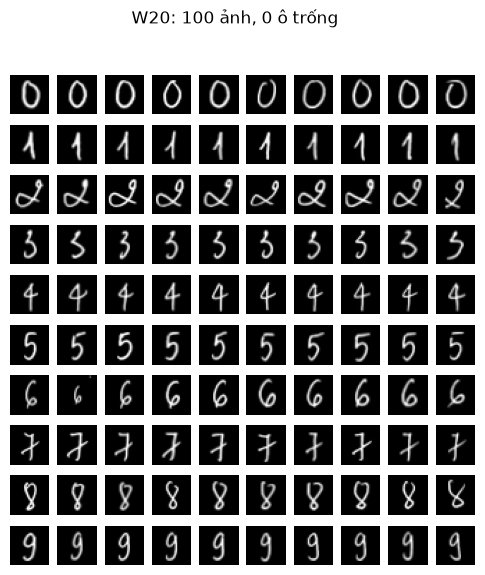

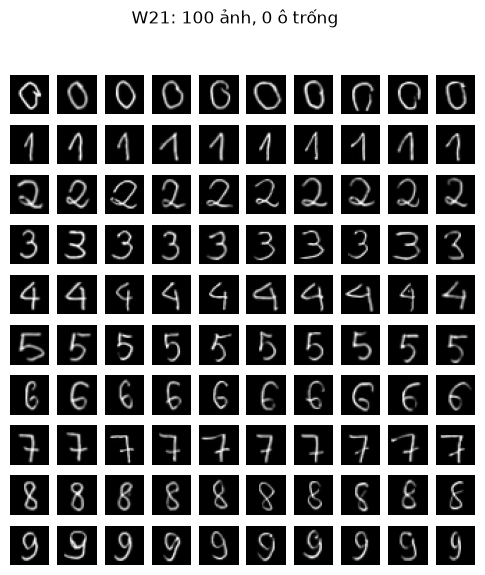

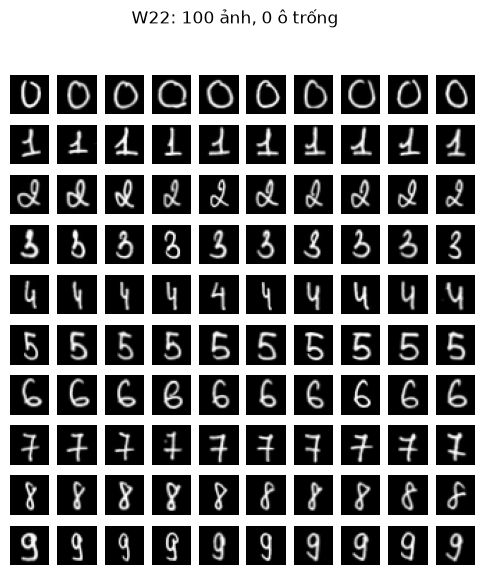

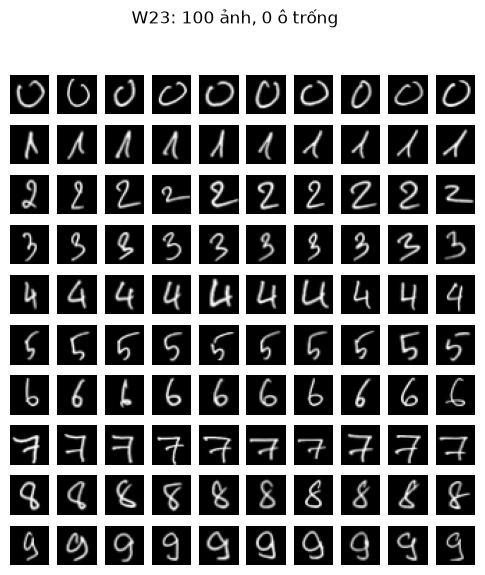

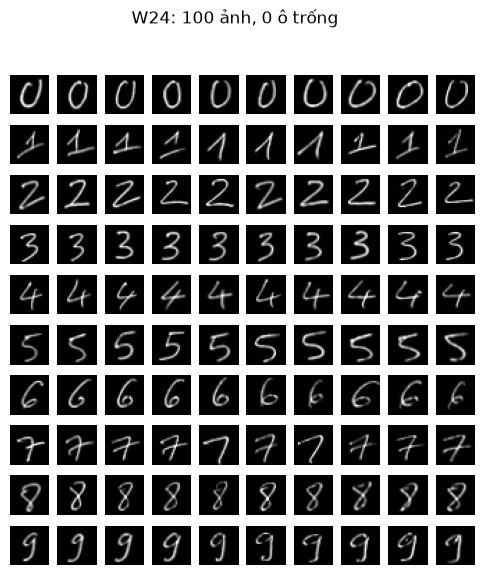

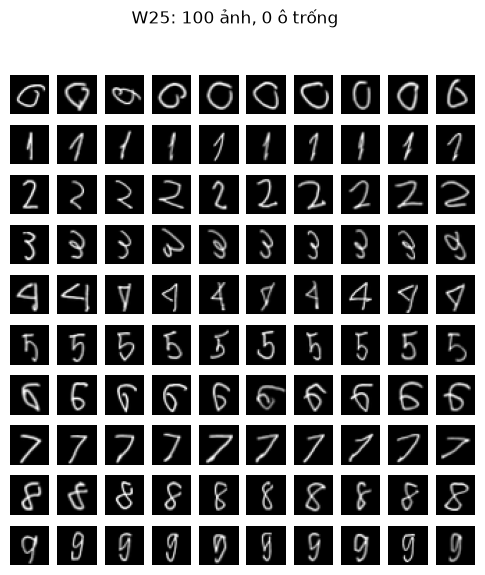

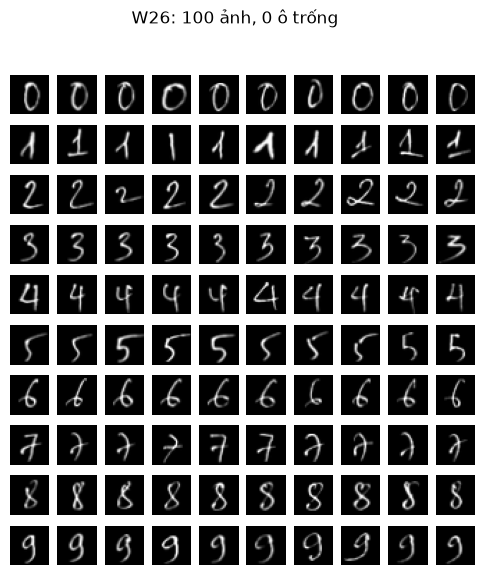

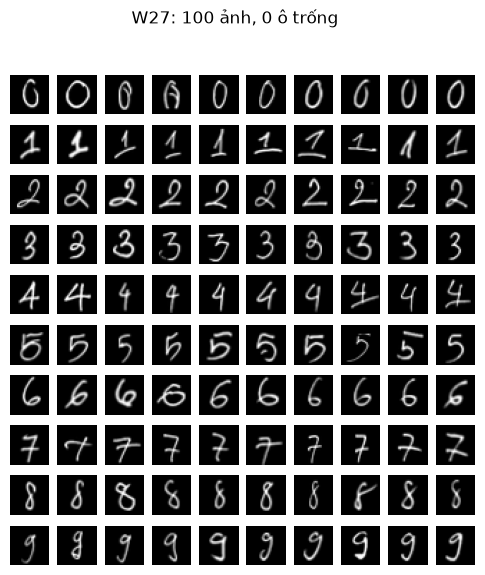

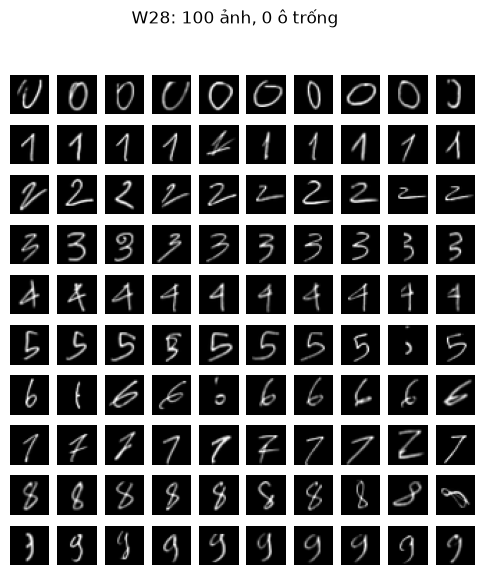

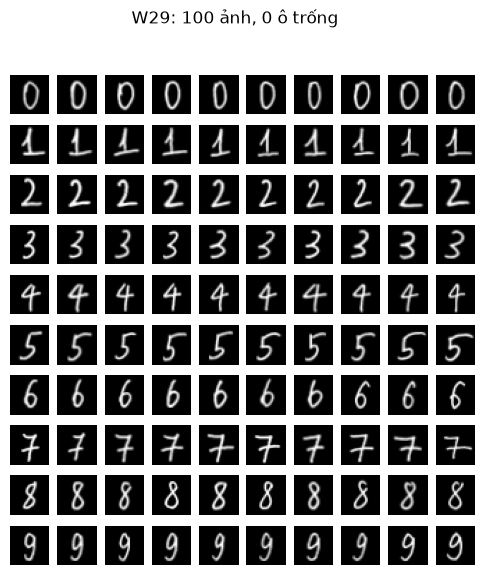

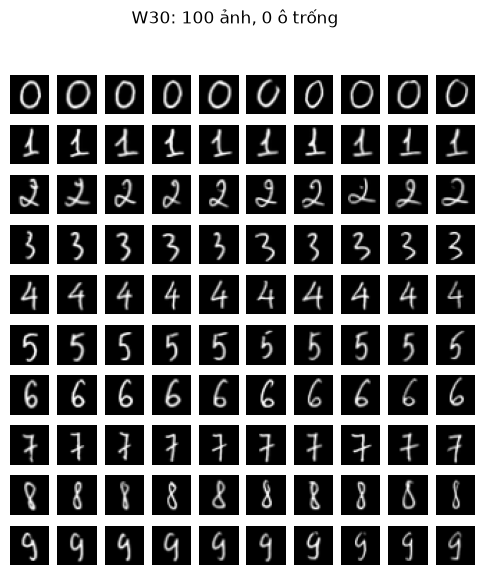

In [152]:
# Ô 2: xem các ô đã cắt của từng phiếu (hàng = chữ số, vị trí giống trên phiếu)
for path in SHEETS:
    try:
        Xs, ys, pos, empty = process_sheet(str(path))
    except ValueError as e:
        print(f"[LỖI] {path.name}: {e}")
        continue
    fig, axes = plt.subplots(10, 10, figsize=(6, 6.4))
    for ax in axes.ravel():
        ax.axis("off")
    for img, (r, c) in zip(Xs, pos):
        axes[r, c].imshow(img.reshape(28, 28), cmap="gray")
    plt.suptitle(f"{path.stem}: {len(ys)} ảnh, {empty} ô trống")
    save_fig(f"vn_cells_{path.stem}"); plt.show()

In [153]:
# Ô 3: gom tất cả phiếu thành data/vn_digits.npz (dùng đường dẫn tuyệt đối để file luôn nằm đúng data/)
if SHEETS:
    build_dataset(str(RAW_DIR), out=str(ROOT / "data" / "vn_digits.npz"))
else:
    print("Chưa có ảnh phiếu trong data/vn_raw/")

W01: 100 ảnh, 0 ô trống
W02: 100 ảnh, 0 ô trống
W03: 100 ảnh, 0 ô trống
W04: 100 ảnh, 0 ô trống
W05: 100 ảnh, 0 ô trống
W06: 100 ảnh, 0 ô trống
W07: 100 ảnh, 0 ô trống
W08: 100 ảnh, 0 ô trống
W09: 100 ảnh, 0 ô trống
W10: 100 ảnh, 0 ô trống
W11: 100 ảnh, 0 ô trống
W12: 100 ảnh, 0 ô trống
W13: 100 ảnh, 0 ô trống
W14: 100 ảnh, 0 ô trống
W15: 100 ảnh, 0 ô trống
W16: 100 ảnh, 0 ô trống
W17: 100 ảnh, 0 ô trống
W18: 100 ảnh, 0 ô trống
W19: 100 ảnh, 0 ô trống
W20: 100 ảnh, 0 ô trống
W21: 100 ảnh, 0 ô trống
W22: 100 ảnh, 0 ô trống
W23: 100 ảnh, 0 ô trống
W24: 100 ảnh, 0 ô trống
W25: 100 ảnh, 0 ô trống
W26: 100 ảnh, 0 ô trống
W27: 100 ảnh, 0 ô trống
W28: 100 ảnh, 0 ô trống
W29: 100 ảnh, 0 ô trống
W30: 100 ảnh, 0 ô trống
Đã lưu D:\Nhan_dang_mau\do_an_gk\data\vn_digits.npz


In [154]:
from data import load_vn, VN_FILE

HAS_VN = VN_FILE.exists()
if HAS_VN:
    X_vn, y_vn, w_vn = load_vn()
    print(f"Tập Việt: {len(y_vn)} ảnh, {len(np.unique(w_vn))} người viết, mỗi lớp {np.bincount(y_vn, minlength=10).tolist()}")
else:
    print("Chưa có data/vn_digits.npz: bỏ qua mục 9.")

Tập Việt: bỏ 20 ô theo vn_exclude.csv
Tập Việt: 2980 ảnh, 30 người viết, mỗi lớp [299, 300, 299, 298, 296, 294, 300, 296, 299, 299]


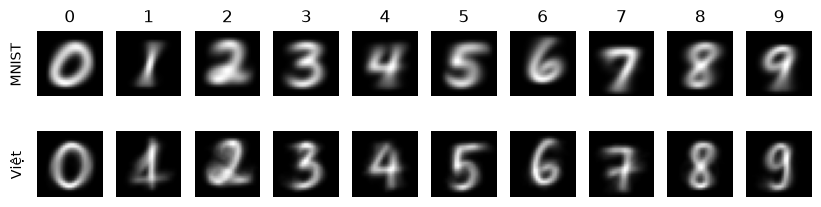

In [155]:
# EDA: ảnh trung bình MNIST (hàng trên) so với tập Việt (hàng dưới)
if HAS_VN:
    fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
    for k in range(10):
        axes[0, k].imshow(X_tr[y_tr == k].mean(0).reshape(28, 28), cmap="gray"); axes[0, k].axis("off")
        axes[1, k].imshow(X_vn[y_vn == k].mean(0).reshape(28, 28), cmap="gray"); axes[1, k].axis("off")
        axes[0, k].set_title(str(k))
    axes[0, 0].text(-12, 14, "MNIST", rotation=90, va="center"); axes[1, 0].text(-12, 14, "Việt", rotation=90, va="center")
    save_fig("vn_mean_images"); plt.show()

In [156]:
# Ba thí nghiệm (a), (b), (c), đánh giá trên cùng phần người viết kiểm tra
if HAS_VN:
    from experiments import augment_dataset, writer_split, evaluate

    def train(name, X, y):
        model = FINAL_MODELS[name]()
        return model.fit(X, y, X_va, y_va) if name in ("Logistic Regression", "MLP") else model.fit(X, y)

    X_aug = augment_dataset(X_tr, copies=1, seed=SEED)
    y_aug = np.concatenate([y_tr, y_tr])
    rows, recall_rows = [], []
    for name in FINAL_MODELS:
        m_a = train(name, X_tr, y_tr)                                   # (a)
        m_b = train(name, X_aug, y_aug)                                 # (b)
        recall_rows.append({"model": name, "MNIST": evaluate(m_a, X_va, y_va)["recall_per_class"],
                            "Việt": evaluate(m_a, X_vn, y_vn)["recall_per_class"]})
        for s in SWEEP_SEEDS:                                           # (c): chia theo người viết
            tr, te = writer_split(w_vn, test_ratio=0.3, seed=s)
            X_c = np.concatenate([X_tr, np.repeat(X_vn[tr], 5, axis=0)])
            y_c = np.concatenate([y_tr, np.repeat(y_vn[tr], 5)])
            m_c = train(name, X_c, y_c)
            rows.append({"model": name, "seed": s,
                         "MNIST val": evaluate(m_a, X_va, y_va)["acc"],
                         "(a)": evaluate(m_a, X_vn[te], y_vn[te])["acc"],
                         "(b)": evaluate(m_b, X_vn[te], y_vn[te])["acc"],
                         "(c)": evaluate(m_c, X_vn[te], y_vn[te])["acc"]})
        print("xong", name)
    vn_table = pd.DataFrame(rows)
    vn_table.to_csv(RESULTS / "vn_experiments.csv", index=False)
    display(vn_table.groupby("model", sort=False)[["MNIST val", "(a)", "(b)", "(c)"]].agg(["mean", "std"]).fillna(0).round(4))

xong Multinomial NB
xong Logistic Regression
Epoch  1/15 | loss 0.2824 | train_acc 0.9146 | val_loss 0.1423 | val_acc 0.9588 | 1.7s
Epoch  2/15 | loss 0.1017 | train_acc 0.9691 | val_loss 0.1046 | val_acc 0.9710 | 1.7s
Epoch  3/15 | loss 0.0728 | train_acc 0.9768 | val_loss 0.1036 | val_acc 0.9692 | 2.3s
Epoch  4/15 | loss 0.0509 | train_acc 0.9839 | val_loss 0.0791 | val_acc 0.9770 | 2.4s
Epoch  5/15 | loss 0.0363 | train_acc 0.9886 | val_loss 0.0797 | val_acc 0.9763 | 2.5s
Epoch  6/15 | loss 0.0284 | train_acc 0.9911 | val_loss 0.0887 | val_acc 0.9768 | 2.6s
Epoch  7/15 | loss 0.0221 | train_acc 0.9933 | val_loss 0.0810 | val_acc 0.9772 | 2.6s
Epoch  8/15 | loss 0.0161 | train_acc 0.9947 | val_loss 0.0870 | val_acc 0.9798 | 2.6s
Epoch  9/15 | loss 0.0089 | train_acc 0.9978 | val_loss 0.0923 | val_acc 0.9773 | 2.6s
Epoch 10/15 | loss 0.0058 | train_acc 0.9988 | val_loss 0.0912 | val_acc 0.9788 | 2.6s
Epoch 11/15 | loss 0.0040 | train_acc 0.9993 | val_loss 0.0844 | val_acc 0.9813 | 2.4

MNIST val          (a)             (b)             (c)  \
                         mean  std    mean     std    mean     std    mean   
model                                                                        
Multinomial NB         0.8210  0.0  0.5751  0.0181  0.5624  0.0173  0.6279   
Logistic Regression    0.9167  0.0  0.6904  0.0445  0.6357  0.0360  0.7844   
MLP                    0.9813  0.0  0.8935  0.0263  0.9029  0.0269  0.9456   
Random Forest          0.9622  0.0  0.6879  0.0251  0.7703  0.0192  0.8789   

                             
                        std  
model                        
Multinomial NB       0.0190  
Logistic Regression  0.0413  
MLP                  0.0237  
Random Forest        0.0352

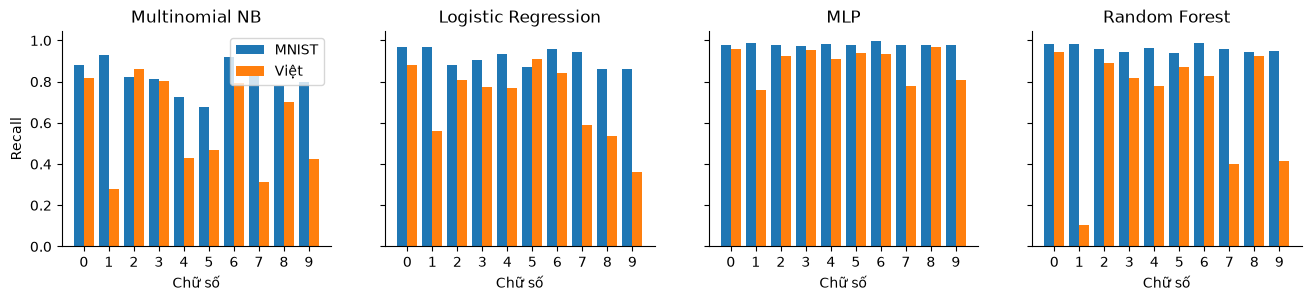

In [157]:
# Recall từng lớp: MNIST so với tập Việt (thí nghiệm a)
if HAS_VN:
    fig, axes = plt.subplots(1, len(recall_rows), figsize=(4 * len(recall_rows), 2.8), sharey=True)
    for ax, r in zip(np.atleast_1d(axes), recall_rows):
        ax.bar(np.arange(10) - 0.2, r["MNIST"], width=0.4, label="MNIST")
        ax.bar(np.arange(10) + 0.2, r["Việt"], width=0.4, label="Việt")
        ax.set_xticks(range(10)); ax.set_title(r["model"]); ax.set_xlabel("Chữ số")
    np.atleast_1d(axes)[0].set_ylabel("Recall"); np.atleast_1d(axes)[0].legend()
    save_fig("vn_recall_per_class"); plt.show()

Epoch  1/15 | loss 0.2824 | train_acc 0.9146 | val_loss 0.1423 | val_acc 0.9588 | 2.7s
Epoch  2/15 | loss 0.1017 | train_acc 0.9691 | val_loss 0.1046 | val_acc 0.9710 | 2.3s
Epoch  3/15 | loss 0.0728 | train_acc 0.9768 | val_loss 0.1036 | val_acc 0.9692 | 3.1s
Epoch  4/15 | loss 0.0509 | train_acc 0.9839 | val_loss 0.0791 | val_acc 0.9770 | 3.1s
Epoch  5/15 | loss 0.0363 | train_acc 0.9886 | val_loss 0.0797 | val_acc 0.9763 | 3.1s
Epoch  6/15 | loss 0.0284 | train_acc 0.9911 | val_loss 0.0887 | val_acc 0.9768 | 3.0s
Epoch  7/15 | loss 0.0221 | train_acc 0.9933 | val_loss 0.0810 | val_acc 0.9772 | 2.9s
Epoch  8/15 | loss 0.0161 | train_acc 0.9947 | val_loss 0.0870 | val_acc 0.9798 | 2.8s
Epoch  9/15 | loss 0.0089 | train_acc 0.9978 | val_loss 0.0923 | val_acc 0.9773 | 2.8s
Epoch 10/15 | loss 0.0058 | train_acc 0.9988 | val_loss 0.0912 | val_acc 0.9788 | 2.8s
Epoch 11/15 | loss 0.0040 | train_acc 0.9993 | val_loss 0.0844 | val_acc 0.9813 | 2.9s
Epoch 12/15 | loss 0.0022 | train_acc 0.999

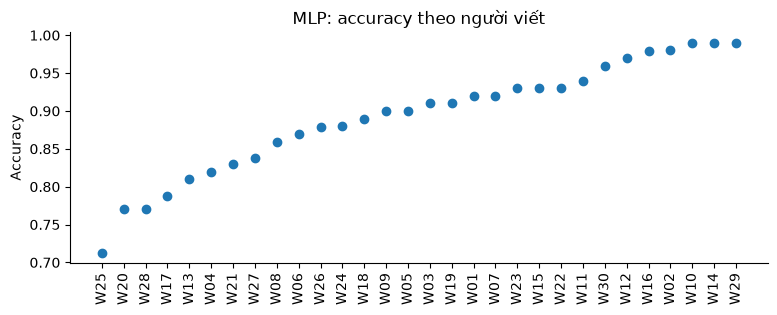

In [158]:
# Accuracy theo từng người viết (mô hình MLP, thí nghiệm a)
if HAS_VN:
    m = train("MLP", X_tr, y_tr)
    pred = m.predict(X_vn)
    per_writer = pd.Series({w: (pred[w_vn == w] == y_vn[w_vn == w]).mean() for w in np.unique(w_vn)}).sort_values()
    plt.figure(figsize=(max(5, 0.3 * len(per_writer)), 3))
    plt.plot(per_writer.index, per_writer.values, "o")
    plt.xticks(rotation=90); plt.ylabel("Accuracy"); plt.title("MLP: accuracy theo người viết")
    save_fig("vn_per_writer"); plt.show()

**Nhận xét thí nghiệm mở rộng**:
* Khi kiểm thử trực tiếp mô hình huấn luyện trên MNIST sang tập dữ liệu viết tay tiếng Việt (thí nghiệm a), độ chính xác của toàn bộ các mô hình đều giảm mạnh do sự khác biệt về phân phối dữ liệu. Trong đó: 
    * MLP: Thể hiện tính bền vững (robustness) tốt nhất, chỉ giảm từ $98.13\%$ xuống còn $89.35\%$
    * Random Forest, Logistic Regression và Multinomial NB: Chịu ảnh hưởng nặng nề hơn rất nhiều, với mức suy giảm độ chính xác dao động từ khoảng $22\%$ đến hơn $27\%$.
* Chữ số 1 là lớp bị sụt giảm chỉ số Recall nghiêm trọng nhất trên hầu hết các mô hình (đặc biệt là Random Forest và Multinomial NB). Nguyên nhân do người Việt thường viết chữ số 1 có thêm nét gạch ngang chân hoặc xéo đỉnh, khác biệt hoàn toàn với nét thẳng đơn giản của MNIST. 
* Kết quả của MLP cho thấy nhận diện phụ thuộc lớn vào phong cách người viết: nhóm người viết đạt độ chính xác cao nhất (như W29, W14, W10) lên tới $\sim 99\%$, trong khi nhóm thấp nhất (như W25) chỉ đạt khoảng $71\%$.
* Thí nghiệm b: Giúp cải thiện rõ rệt hiệu năng cho Random Forest (tăng lên $77.03\%$) và MLP ($90.29\%$), nhưng ít tác dụng hoặc làm giảm nhẹ ở các mô hình tuyến tính vốn nhạy cảm với vị trí pixel gốc.
* Thí nghiệm c:  Mang lại thay đổi lớn trên toàn bộ các mô hình, giúp MLP phục hồi lên mức cao nhất $94.56\%$, Random Forest tăng lên $87.89\%$, qua đó thu hẹp thành công khoảng cách miền (domain gap) giữa chữ viết tay Việt và tập MNIST gốc.

## 10. Nâng cao: tăng cường dữ liệu và thí nghiệm độ bền

Huấn luyện lại 4 mô hình với cấu hình cuối (`FINAL_MODELS`), **không** và **có** augmentation, rồi đo accuracy khi ảnh kiểm tra bị xoay, dịch, thêm nhiễu.

In [159]:
from experiments import augment_dataset, robustness, LEVELS

X_aug = augment_dataset(X_tr, copies=1, seed=SEED)          # gốc + 1 bản biến đổi
y_aug = np.concatenate([y_tr, y_tr])
NEEDS_VAL = ("Logistic Regression", "MLP")                    # các mô hình cần X_val cho fit

def fit_final(name, X, y):
    model = FINAL_MODELS[name]()
    return model.fit(X, y, X_va, y_va) if name in NEEDS_VAL else model.fit(X, y)

ROBUST_MODELS = {}
for name in FINAL_MODELS:
    t = time.perf_counter()
    ROBUST_MODELS[name] = fit_final(name, X_tr, y_tr)
    ROBUST_MODELS[name + " + aug"] = fit_final(name, X_aug, y_aug)
    print(f"{name:20s} xong ({time.perf_counter() - t:.1f} s)")

Multinomial NB       xong (1.0 s)
Logistic Regression  xong (35.5 s)
Epoch  1/15 | loss 0.2824 | train_acc 0.9146 | val_loss 0.1423 | val_acc 0.9588 | 2.3s
Epoch  2/15 | loss 0.1017 | train_acc 0.9691 | val_loss 0.1046 | val_acc 0.9710 | 2.3s
Epoch  3/15 | loss 0.0728 | train_acc 0.9768 | val_loss 0.1036 | val_acc 0.9692 | 2.7s
Epoch  4/15 | loss 0.0509 | train_acc 0.9839 | val_loss 0.0791 | val_acc 0.9770 | 2.8s
Epoch  5/15 | loss 0.0363 | train_acc 0.9886 | val_loss 0.0797 | val_acc 0.9763 | 2.8s
Epoch  6/15 | loss 0.0284 | train_acc 0.9911 | val_loss 0.0887 | val_acc 0.9768 | 2.8s
Epoch  7/15 | loss 0.0221 | train_acc 0.9933 | val_loss 0.0810 | val_acc 0.9772 | 2.9s
Epoch  8/15 | loss 0.0161 | train_acc 0.9947 | val_loss 0.0870 | val_acc 0.9798 | 3.1s
Epoch  9/15 | loss 0.0089 | train_acc 0.9978 | val_loss 0.0923 | val_acc 0.9773 | 3.0s
Epoch 10/15 | loss 0.0058 | train_acc 0.9988 | val_loss 0.0912 | val_acc 0.9788 | 2.9s
Epoch 11/15 | loss 0.0040 | train_acc 0.9993 | val_loss 0.084

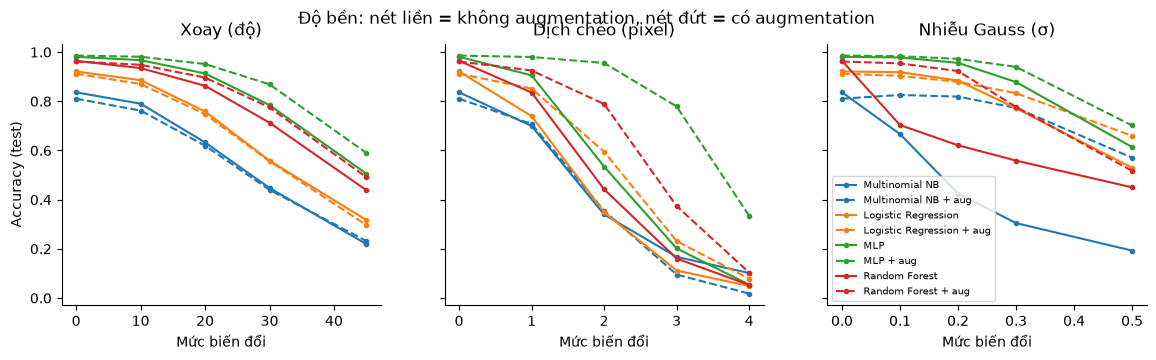

cot,rotate 0.0,rotate 30.0,shift 3.0
model,,,
Logistic Regression,0.9213,0.5583,0.1117
Logistic Regression + aug,0.9124,0.5562,0.2313
MLP,0.9809,0.7844,0.2019
MLP + aug,0.9858,0.8688,0.7791
Multinomial NB,0.8364,0.4475,0.1672
Multinomial NB + aug,0.8106,0.4399,0.0953
Random Forest,0.9645,0.7129,0.1605
Random Forest + aug,0.9618,0.7749,0.3739


In [160]:
X_eval, y_eval, eval_name = (X_te, y_te, "test") if RUN_TEST else (X_va, y_va, "val")
rob = robustness(ROBUST_MODELS, X_eval, y_eval)
rob.to_csv(RESULTS / f"robustness_{eval_name}.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
titles = {"rotate": "Xoay (độ)", "shift": "Dịch chéo (pixel)", "noise": "Nhiễu Gauss (σ)"}
for ax, kind in zip(axes, LEVELS):
    g = rob[rob.kind == kind]
    for i, name in enumerate(FINAL_MODELS):
        color = f"C{i}"
        for suffix, ls in [("", "-"), (" + aug", "--")]:
            gg = g[g.model == name + suffix]
            ax.plot(gg.level, gg.acc, ls=ls, marker="o", ms=3, color=color, label=name + suffix)
    ax.set_title(titles[kind]); ax.set_xlabel("Mức biến đổi")
axes[0].set_ylabel(f"Accuracy ({eval_name})")
axes[-1].legend(fontsize=7, loc="lower left")
plt.suptitle("Độ bền: nét liền = không augmentation, nét đứt = có augmentation")
save_fig(f"robustness_{eval_name}"); plt.show()

# Bảng gọn cho báo cáo: accuracy sạch, xoay 30°, dịch 3 px
pick = rob[((rob.kind == "rotate") & rob.level.isin([0, 30])) | ((rob.kind == "shift") & (rob.level == 3))]
pick = pick.assign(cot=pick.kind + " " + pick.level.astype(str))
display(pick.pivot(index="model", columns="cot", values="acc").round(4))

**Nhận xét độ bền**:
* Mức biến đổi nào thì mỗi mô hình bắt đầu “sụp”:
    * Phép Xoay (Độ): Hiệu năng của hầu hết các mô hình bắt đầu sụp giảm rõ rệt khi góc xoay vượt quá $10^\circ - 20^\circ$, và rớt mạnh xuống dưới $50\%$ khi góc xoay đạt $45^\circ$.
    * Dịch chéo (Pixel): Các mô hình chịu tổn thương rất nhanh khi dịch chuyển vượt quá $1$ pixel, đặc biệt sụp đổ hoàn toàn (accuracy $< 20\%$) khi độ dịch chuyển đạt từ $3 - 4$ pixel.
    * Nhiễu Gauss ($\sigma$): Điểm sụp đổ diễn ra khi độ lệch chuẩn nhiễu vượt ngưỡng $0.1 - 0.2$, trong đó Multinomial NB là mô hình nhạy cảm và sụp đổ sớm nhất.
* Việc áp dụng Data Augmentation (đường nét đứt so với nét liền) giúp dịch chuyển đáng kể điểm sụp hiệu năng về phía trước, tăng cường sức chống chịu rõ rệt cho mô hình:
    * Đặc biệt ở biểu đồ Dịch chéo, augmentation giúp duy trì độ chính xác cao hơn hẳn ở mức dịch chuyển $2$ và $3$ pixel (ví dụ MLP + aug giữ vững độ ổn định tốt hơn hẳn không aug).
    * Đối với phép Xoay và Nhiễu Gauss, augmentation cũng giúp các đường cong dịch chuyển lên trên, làm chậm tốc độ suy giảm accuracy khi mức độ nhiễu tăng cao.
* Accuracy trên ảnh sạch có giảm ở mô hình đơn giản không:
    * Ở một số mô hình hoặc cấu hình (ví dụ Multinomial NB giảm từ $0.8364$ xuống $0.8106$, hoặc Logistic Regression + aug so với bản gốc), việc huấn luyện với dữ liệu tăng cường (augmentation) có thể làm giảm nhẹ độ chính xác trên ảnh sạch ban đầu ($\sigma = 0$, mức dịch = $0$).
    * Lý do: Do mô hình phải chia sẻ "dung lượng học" để thích ứng với các biến thể nhiễu và dịch chuyển, dẫn đến độ khớp trên tập sạch cơ sở có thể thấp hơn một chút so với mô hình chỉ chuyên hóa trên ảnh sạch hoàn toàn.
* So với thí nghiệm (b) ở mục 9, augmentation có giúp đọc chữ người Việt không?
    * Các phép biến đổi trong augmentation (như xoay nhẹ, dịch chuyển pixel, thêm nhiễu) mô phỏng khá sát các biến động về nét viết tay thực tế của con người (tương ứng tập Việt)
    * việc huấn luyện có augmentation giúp mô hình làm quen tốt hơn với các biến dạng hình học và nét chữ không chuẩn hóa, từ đó cải thiện đáng kể khả năng tổng quát hóa khi đưa sang đọc tập chữ viết tay tiếng Việt

## 11. Lưu mô hình cho demo (Mục 11.4)

In [161]:
import pickle

MODEL_DIR = RESULTS / "models"
MODEL_DIR.mkdir(exist_ok=True)

if RUN_TEST and "final" in globals():
    to_save = {"naive_bayes": final["Multinomial NB"], "logistic": final["Logistic Regression"],
               "mlp": final["MLP"], "random_forest": final["Random Forest"]}
else:
    to_save = {"naive_bayes": nb, "logistic": lr_model, "mlp": mlp, "random_forest": rf}

for fname, m in to_save.items():
    if hasattr(m, "A"):          # MLP giữ kết quả trung gian của lần forward cuối: xoá cho file nhỏ
        m.A = m.Z = None
    with open(MODEL_DIR / f"{fname}.pkl", "wb") as f:
        pickle.dump(m, f)
    print(f"Đã lưu {fname}.pkl ({(MODEL_DIR / f'{fname}.pkl').stat().st_size / 1e6:.1f} MB)")

Đã lưu naive_bayes.pkl (0.1 MB)
Đã lưu logistic.pkl (0.1 MB)
Đã lưu mlp.pkl (1.9 MB)
Đã lưu random_forest.pkl (35.1 MB)


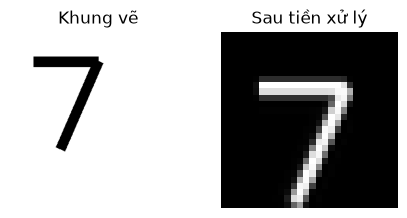

naive_bayes     đoán: 7
logistic        đoán: 7
mlp             đoán: 7
random_forest   đoán: 7


In [162]:
# Kiểm tra demo ngay trong notebook (không cần Gradio): ảnh vẽ giả lập -> tiền xử lý -> dự đoán
from PIL import Image, ImageDraw
from vn_digits import clean_cell, to_mnist

canvas = Image.new("L", (300, 300), 255)                      # nền trắng
ImageDraw.Draw(canvas).line([(40, 50), (150, 50), (85, 200)], fill=0, width=18)   # số 7 vẽ lệch góc
x = to_mnist(clean_cell(np.asarray(canvas, dtype=np.float32), min_contrast=40)).reshape(1, 784)

fig, axes = plt.subplots(1, 2, figsize=(5, 2.4))
axes[0].imshow(canvas, cmap="gray"); axes[0].set_title("Khung vẽ"); axes[0].axis("off")
axes[1].imshow(x.reshape(28, 28), cmap="gray"); axes[1].set_title("Sau tiền xử lý"); axes[1].axis("off")
plt.show()
for fname, m in to_save.items():
    print(f"{fname:15s} đoán: {m.predict(x)[0]}")